# Notebook 2 — Tensor de tiempos de viaje y baseline histórico $K=0$

**Proyecto Integrador — Equipo 42 · Route Intelligence**

> **Alcance de esta notebook.** A partir del dataset de tiempos por arista construido en la Notebook 1, se genera para cada instante disponible la matriz dirigida de tiempos mínimos de viaje entre los 13 macronodos de la red experimental. La secuencia de estas matrices constituye el dataset utilizado para establecer el baseline histórico $K=0$.
>
> Para cada instante $t$, la matriz de referencia $T_{\mathrm{ref}}(t)$ se obtiene asignando a las aristas sus tiempos observados y calculando caminos de tiempo mínimo sobre la red dirigida. Al apilar las matrices correspondientes a todo el periodo se obtiene un tensor temporal que representa la evolución de los tiempos origen-destino de la red.
>
> El escenario $K=0$ representa la situación en la que no se dispone de ninguna observación actual de la matriz. Su estimación depende exclusivamente del comportamiento histórico de las entradas origen-destino. Este baseline servirá posteriormente como referencia para evaluar métodos que incorporen un número reducido de observaciones actuales, $K>0$.
>
> Para evitar fuga de información temporal, la construcción de las referencias históricas y su evaluación respetan estrictamente la separación cronológica entre entrenamiento, validación y prueba.

## 1. Carga del dataset derivado

La Notebook 1 produjo una representación de la red y sus series temporales de
tiempo de recorrido. Esta notebook utiliza directamente esos productos, sin
repetir la preparación de PEMS-BAY, la construcción espacial de la red ni la
asignación de longitudes.

El dataset contiene los nodos del núcleo de enrutamiento, sus aristas dirigidas,
los atributos necesarios para identificarlas y una serie temporal de tiempo de
recorrido para cada arista.

In [ ]:
# ------------------------------------------------------------
# 1. Carga del dataset derivado
# ------------------------------------------------------------

from pathlib import Path
import json

import numpy as np
import pandas as pd

from google.colab import drive

drive.mount('/content/drive')

DATASET_DIR = Path(
    '/content/drive/MyDrive/Route Intelligence/routing_dataset_v1'
)

nodes_path = DATASET_DIR / 'nodes.csv'
edges_path = DATASET_DIR / 'edges.csv'
times_path = DATASET_DIR / 'edge_travel_times.parquet'
manifest_path = DATASET_DIR / 'manifest.json'


# ------------------------------------------------------------
# Carga
# ------------------------------------------------------------

nodes = pd.read_csv(
    nodes_path,
    dtype={'node_id': str}
)

edges = pd.read_csv(
    edges_path,
    dtype={
        'edge_id': str,
        'from': str,
        'to': str,
        'sensor_1': str,
        'sensor_2': str
    }
)

edge_travel_times = pd.read_parquet(
    times_path
)

edge_travel_times.index = pd.to_datetime(
    edge_travel_times.index
)

with open(
    manifest_path,
    'r',
    encoding='utf-8'
) as f:
    manifest = json.load(f)


# ------------------------------------------------------------
# Validaciones
# ------------------------------------------------------------

assert len(nodes) == manifest['network']['nodes']
assert len(edges) == manifest['network']['directed_edges']

assert edge_travel_times.shape == (
    manifest['temporal_data']['observations'],
    manifest['temporal_data']['edges']
)

assert (
    edges['edge_id'].tolist()
    == edge_travel_times.columns.tolist()
)

assert np.isfinite(
    edge_travel_times.to_numpy()
).all()

assert (
    edge_travel_times.to_numpy() > 0
).all()


print('Dataset cargado correctamente.')
print()
print('Nodos:', len(nodes))
print('Aristas:', len(edges))
print('Matriz temporal:', edge_travel_times.shape)
print(
    'Periodo:',
    edge_travel_times.index.min(),
    '→',
    edge_travel_times.index.max()
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset cargado correctamente.

Nodos: 322
Aristas: 345
Matriz temporal: (52116, 345)
Periodo: 2017-01-01 00:00:00 → 2017-06-30 23:55:00


## 2. Análisis exploratorio del dataset derivado

Antes de definir el protocolo experimental se examinan las propiedades espaciales y temporales del dataset construido en la Notebook 1. El objetivo es verificar que la representación preserve patrones de movilidad plausibles y caracterizar la variación temporal, espacial y direccional de los tiempos de recorrido que posteriormente determinarán las matrices de viaje de la red.

Este análisis es descriptivo. Las decisiones de ajuste y evaluación de las referencias históricas se realizarán posteriormente utilizando únicamente los periodos correspondientes del protocolo temporal.

### 2.1 Estructura del dataset derivado

Se inspecciona la estructura de los archivos derivados para verificar la composición del núcleo de enrutamiento, los tipos de nodos y aristas y la correspondencia entre la representación espacial y las series temporales utilizadas en los análisis posteriores.

In [ ]:
# ------------------------------------------------------------
# 2.1 Estructura del dataset derivado
# ------------------------------------------------------------

print('Columnas de nodes:')
print(nodes.columns.tolist())

print()
print('Columnas de edges:')
print(edges.columns.tolist())

print()
print('Tipos de nodo:')
print(nodes['node_type'].value_counts())

print()
print('Tipos de arista:')
print(edges['edge_type'].value_counts())

Columnas de nodes:
['node_id', 'node_type', 'corridor', 'osm_freeways', 'latitude', 'longitude']

Columnas de edges:
['edge_id', 'from', 'to', 'corridor', 'edge_type', 'node_id', 'anchor_type', 'distance_km', 'distance_method', 'sensor_1', 'sensor_2', 'speed_rule']

Tipos de nodo:
node_type
sensor         309
interchange     13
Name: count, dtype: int64

Tipos de arista:
edge_type
corridor                 273
sensor_to_interchange     36
interchange_to_sensor     36
Name: count, dtype: int64


### 2.2 Visualización de la topología de la red

Se representa espacialmente el núcleo de enrutamiento obtenido en la Notebook 1.
La figura permite verificar la continuidad de los corredores, la ubicación de los
macronodos y las conexiones dirigidas incorporadas entre ellos.

Las líneas representan conexiones funcionales del grafo experimental y no deben
interpretarse como una reconstrucción exacta de la geometría de las carreteras.
Los sensores conservan sus coordenadas geográficas originales, mientras que los
macronodos representan zonas funcionales de intercambio entre corredores.

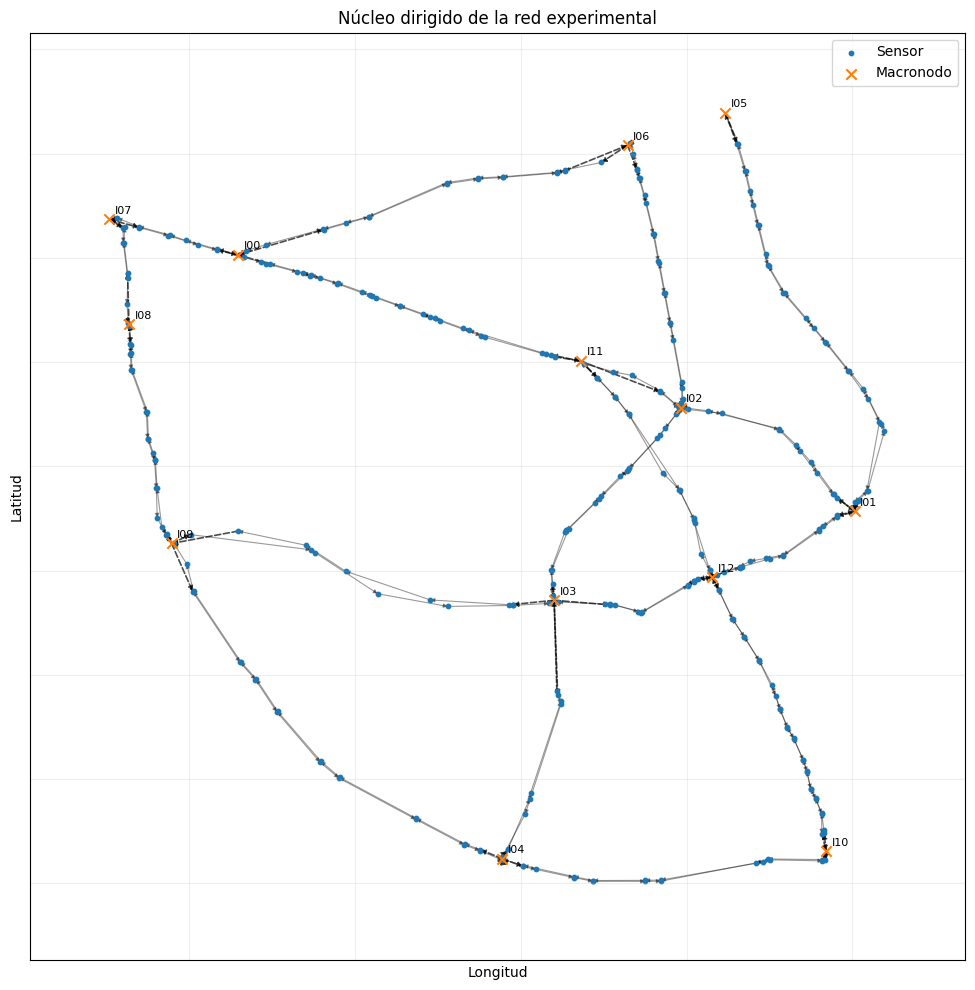

In [ ]:
# ------------------------------------------------------------
# 2.2 Visualización de la topología de la red
# ------------------------------------------------------------

import matplotlib.pyplot as plt
import networkx as nx


# ------------------------------------------------------------
# Coordenadas
# ------------------------------------------------------------

node_coords = (
    nodes[
        ['node_id', 'longitude', 'latitude']
    ]
    .copy()
)

node_coords['node_id'] = (
    node_coords['node_id'].astype(str)
)

assert node_coords[
    ['longitude', 'latitude']
].notna().all().all()

pos = {
    row['node_id']: (
        float(row['longitude']),
        float(row['latitude'])
    )
    for _, row in node_coords.iterrows()
}


# ------------------------------------------------------------
# Grafo para visualización
# ------------------------------------------------------------

G_view = nx.DiGraph()

G_view.add_nodes_from(
    nodes['node_id'].astype(str)
)

G_view.add_edges_from(
    zip(
        edges['from'].astype(str),
        edges['to'].astype(str)
    )
)


corridor_edges_plot = [
    (str(row['from']), str(row['to']))
    for _, row in edges.iterrows()
    if row['edge_type'] == 'corridor'
]

interchange_edges_plot = [
    (str(row['from']), str(row['to']))
    for _, row in edges.iterrows()
    if row['edge_type'] != 'corridor'
]


sensor_nodes = (
    nodes.loc[
        nodes['node_type'] == 'sensor',
        'node_id'
    ]
    .astype(str)
    .tolist()
)

interchange_nodes = (
    nodes.loc[
        nodes['node_type'] == 'interchange',
        'node_id'
    ]
    .astype(str)
    .tolist()
)


# ------------------------------------------------------------
# Figura
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(12, 10)
)

# Aristas intracorredor
nx.draw_networkx_edges(
    G_view,
    pos,
    edgelist=corridor_edges_plot,
    ax=ax,
    arrows=True,
    arrowsize=6,
    width=0.8,
    alpha=0.40,
    node_size=0
)

# Conexiones con macronodos
nx.draw_networkx_edges(
    G_view,
    pos,
    edgelist=interchange_edges_plot,
    ax=ax,
    arrows=True,
    arrowsize=7,
    width=1.2,
    style='dashed',
    alpha=0.70,
    node_size=0
)

# Sensores
sensor_xy = np.array(
    [pos[node] for node in sensor_nodes]
)

ax.scatter(
    sensor_xy[:, 0],
    sensor_xy[:, 1],
    s=10,
    label='Sensor'
)

# Macronodos
interchange_xy = np.array(
    [pos[node] for node in interchange_nodes]
)

ax.scatter(
    interchange_xy[:, 0],
    interchange_xy[:, 1],
    s=55,
    marker='x',
    linewidths=1.5,
    label='Macronodo'
)

# Etiquetas únicamente para macronodos
for node in interchange_nodes:

    x, y = pos[node]

    ax.annotate(
        node,
        (x, y),
        xytext=(4, 4),
        textcoords='offset points',
        fontsize=8
    )


# Corrección aproximada de la relación espacial latitud-longitud
mean_lat = nodes['latitude'].mean()

ax.set_aspect(
    1 / np.cos(
        np.deg2rad(mean_lat)
    )
)

ax.set_xlabel('Longitud')
ax.set_ylabel('Latitud')
ax.set_title(
    'Núcleo dirigido de la red experimental'
)

ax.legend()
ax.grid(
    alpha=0.20
)

plt.tight_layout()
plt.show()

La representación permite verificar la continuidad general de los corredores y la
integración de los macronodos en el núcleo de enrutamiento. Los cruces geométricos
entre segmentos no implican por sí mismos una conexión entre corredores; la
conectividad queda determinada exclusivamente por las aristas del grafo.

La figura constituye una representación funcional de la red experimental y no una
reconstrucción de la geometría exacta de las carreteras.

### 2.2.1 Visualización de la red con separación por sentido

Para facilitar la interpretación de la red dirigida, se aplica un pequeño desplazamiento gráfico a los sensores de acuerdo con el sentido de circulación de cada corredor. Los sensores asociados con rutas hacia el norte se desplazan ligeramente hacia la derecha, los de sentido sur hacia la izquierda, los de sentido este hacia abajo y los de sentido oeste hacia arriba.

Este desplazamiento se utiliza únicamente con fines de visualización y no modifica la topología de la red, las distancias entre nodos ni los tiempos de recorrido empleados en los análisis posteriores. Los macronodos permanecen en sus coordenadas geográficas originales.

Los corredores pertenecientes a una misma autopista se representan con el mismo color, mientras que las flechas indican el sentido de circulación. Esta representación permite distinguir con mayor claridad los corredores dirigidos que, en sus coordenadas originales, se superponen visualmente.

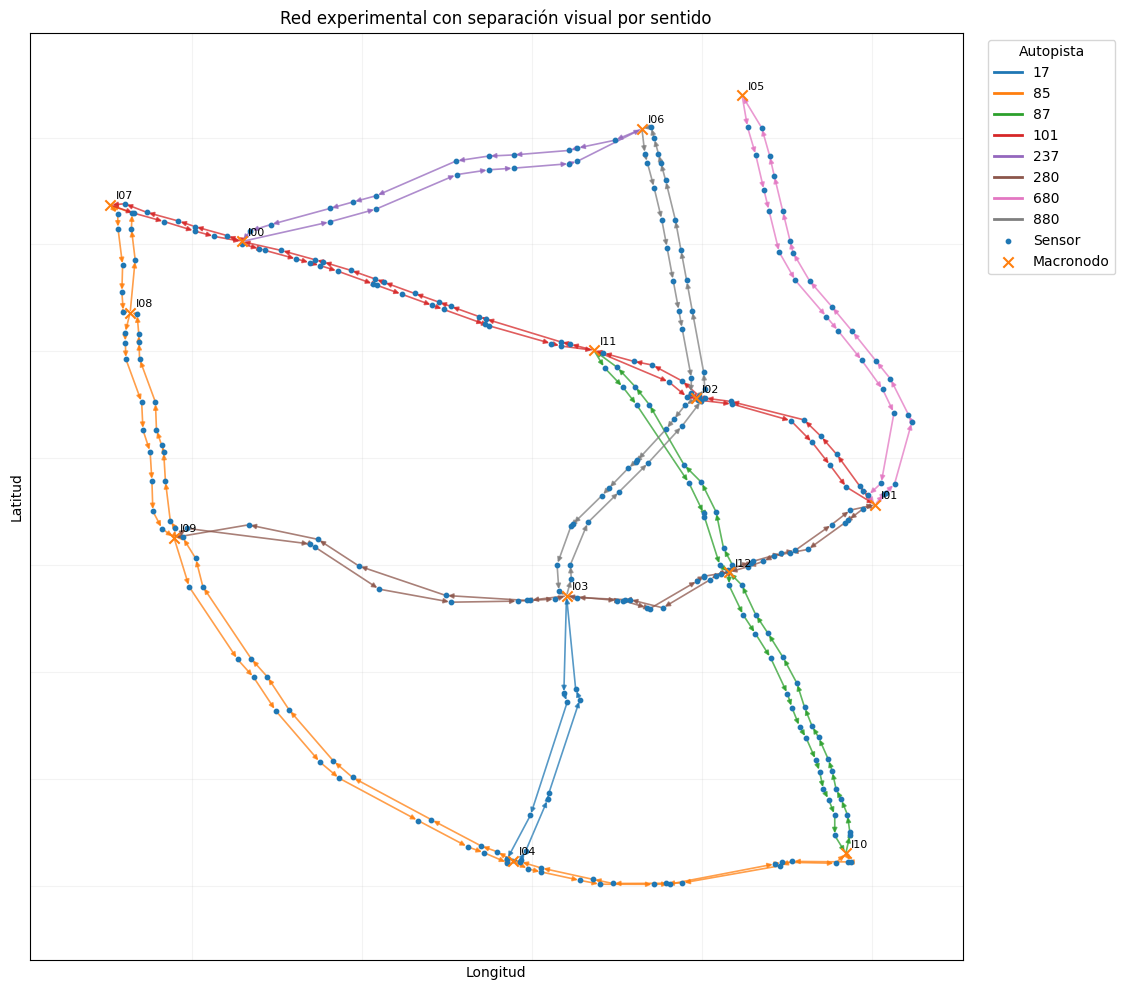

In [ ]:
# ------------------------------------------------------------
# 2.2.1 Separación visual de corredores por sentido
# ------------------------------------------------------------

import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

from matplotlib.lines import Line2D


# ------------------------------------------------------------
# Grafo de visualización
# ------------------------------------------------------------

G_view = nx.DiGraph()

G_view.add_nodes_from(
    nodes['node_id'].astype(str)
)

G_view.add_edges_from(
    zip(
        edges['from'].astype(str),
        edges['to'].astype(str)
    )
)


# ------------------------------------------------------------
# Tipos de nodo
# ------------------------------------------------------------

sensor_nodes = (
    nodes.loc[
        nodes['node_type'] == 'sensor',
        'node_id'
    ]
    .astype(str)
    .tolist()
)

interchange_nodes = (
    nodes.loc[
        nodes['node_type'] == 'interchange',
        'node_id'
    ]
    .astype(str)
    .tolist()
)


# ------------------------------------------------------------
# Posiciones geográficas originales
# ------------------------------------------------------------

pos_shifted = {
    str(row['node_id']): np.array([
        float(row['longitude']),
        float(row['latitude'])
    ])
    for _, row in nodes.iterrows()
}


# ------------------------------------------------------------
# Magnitud del desplazamiento visual
# ------------------------------------------------------------

lon_span = (
    nodes['longitude'].max()
    - nodes['longitude'].min()
)

lat_span = (
    nodes['latitude'].max()
    - nodes['latitude'].min()
)

SHIFT_FRAC = 0.008

dx = SHIFT_FRAC * lon_span
dy = SHIFT_FRAC * lat_span


# ------------------------------------------------------------
# Desplazamiento de sensores según sentido de circulación
#
# Se utiliza una convención coherente con circulación
# por la derecha:
#
# N -> derecha
# S -> izquierda
# E -> abajo
# W -> arriba
#
# El desplazamiento es exclusivamente gráfico.
# ------------------------------------------------------------

for _, row in nodes.loc[
    nodes['node_type'] == 'sensor'
].iterrows():

    node = str(row['node_id'])
    corridor = str(row['corridor'])

    direction = corridor.split('-')[-1]

    if direction == 'N':
        pos_shifted[node][0] += dx

    elif direction == 'S':
        pos_shifted[node][0] -= dx

    elif direction == 'E':
        pos_shifted[node][1] -= dy

    elif direction == 'W':
        pos_shifted[node][1] += dy


# ------------------------------------------------------------
# Autopistas físicas y colores
# ------------------------------------------------------------

freeways = sorted(
    edges['corridor']
    .dropna()
    .astype(str)
    .str.split('-')
    .str[0]
    .unique(),
    key=lambda x: int(x)
)

color_cycle = (
    plt.rcParams[
        'axes.prop_cycle'
    ]
    .by_key()['color']
)

freeway_colors = {
    freeway: color_cycle[
        i % len(color_cycle)
    ]
    for i, freeway in enumerate(freeways)
}


# ------------------------------------------------------------
# Figura
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(13, 10)
)


# ------------------------------------------------------------
# Aristas por autopista
#
# Ambos sentidos de una misma autopista conservan
# el mismo color.
# ------------------------------------------------------------

for freeway in freeways:

    freeway_edges = [
        (
            str(row['from']),
            str(row['to'])
        )
        for _, row in edges.iterrows()
        if (
            pd.notna(row['corridor'])
            and str(row['corridor']).split('-')[0]
            == freeway
        )
    ]

    nx.draw_networkx_edges(
        G_view,
        pos_shifted,
        edgelist=freeway_edges,
        ax=ax,
        edge_color=freeway_colors[freeway],
        arrows=True,
        arrowsize=7,
        width=1.2,
        alpha=0.75,
        node_size=10
    )


# ------------------------------------------------------------
# Sensores
# ------------------------------------------------------------

sensor_xy = np.array([
    pos_shifted[node]
    for node in sensor_nodes
])

sensor_handle = ax.scatter(
    sensor_xy[:, 0],
    sensor_xy[:, 1],
    s=10,
    zorder=3,
    label='Sensor'
)


# ------------------------------------------------------------
# Macronodos
#
# Los macronodos permanecen en su posición geográfica
# original; sólo se desplazan los sensores de cada corredor.
# ------------------------------------------------------------

macro_xy = np.array([
    pos_shifted[node]
    for node in interchange_nodes
])

macro_handle = ax.scatter(
    macro_xy[:, 0],
    macro_xy[:, 1],
    s=55,
    marker='x',
    linewidths=1.5,
    zorder=4,
    label='Macronodo'
)


# Etiquetas de macronodos
for node in interchange_nodes:

    x, y = pos_shifted[node]

    ax.annotate(
        node,
        (x, y),
        xytext=(4, 4),
        textcoords='offset points',
        fontsize=8
    )


# ------------------------------------------------------------
# Leyenda de colores por autopista
# ------------------------------------------------------------

freeway_handles = [
    Line2D(
        [0],
        [0],
        color=freeway_colors[freeway],
        linewidth=2.0,
        label=freeway
    )
    for freeway in freeways
]

legend_handles = (
    freeway_handles
    + [
        sensor_handle,
        macro_handle
    ]
)

ax.legend(
    handles=legend_handles,
    title='Autopista',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)


# ------------------------------------------------------------
# Formato
# ------------------------------------------------------------

mean_lat = nodes['latitude'].mean()

ax.set_aspect(
    1 / np.cos(
        np.deg2rad(mean_lat)
    )
)

ax.set_xlabel('Longitud')
ax.set_ylabel('Latitud')

ax.set_title(
    'Red experimental con separación visual por sentido'
)

ax.grid(
    alpha=0.15
)

plt.tight_layout()
plt.show()

La separación visual permite identificar los dos sentidos de circulación sin alterar la estructura de la red experimental. Esta representación se utilizará como referencia gráfica en los análisis posteriores de velocidades y tiempos de recorrido.

### 2.3 Dinámica temporal del tráfico

Una vez verificada la estructura espacial de la red, se examina la variación temporal del tráfico representado en el dataset. El objetivo es identificar patrones históricos recurrentes que permitan caracterizar la evolución temporal de la red y que posteriormente puedan aprovecharse para estimar los tiempos origen-destino cuando no se disponga de observaciones actuales de la matriz.

#### 2.3.1 Reconstrucción de velocidades por arista

El dataset derivado almacena tiempos de recorrido por arista, $\tau_e(t)$, expresados en minutos. Para facilitar la interpretación de la dinámica del tráfico se reconstruye la velocidad asociada a cada arista mediante

$$
v_e(t)=\frac{60\,d_e}{\tau_e(t)},
$$

donde $d_e$ es la longitud de la arista en kilómetros y $v_e(t)$ se expresa en km/h.

Esta operación es únicamente la inversión de la transformación utilizada en la Notebook 1 para obtener los tiempos de recorrido. Por tanto, no incorpora información adicional al dataset ni modifica las observaciones utilizadas posteriormente para la estimación.

In [ ]:
# ------------------------------------------------------------
# 2.3.1 Reconstrucción de velocidades por arista
# ------------------------------------------------------------

# Longitud de cada arista, alineada con las columnas
# de la matriz temporal.
edge_distance_km = (
    edges
    .set_index('edge_id')['distance_km']
    .reindex(edge_travel_times.columns)
)

# Validaciones de alineación y distancias.
assert edge_distance_km.notna().all()
assert (edge_distance_km > 0).all()

# ------------------------------------------------------------
# Reconstrucción de velocidades
#
# v_e(t) = 60 * d_e / tau_e(t)
#
# d_e       : km
# tau_e(t)  : min
# v_e(t)    : km/h
# ------------------------------------------------------------

edge_speeds_kmh = edge_travel_times.rdiv(
    60.0 * edge_distance_km,
    axis='columns'
)

# ------------------------------------------------------------
# Validaciones
# ------------------------------------------------------------

assert edge_speeds_kmh.shape == edge_travel_times.shape

assert (
    edge_speeds_kmh.columns.tolist()
    == edge_travel_times.columns.tolist()
)

assert edge_speeds_kmh.index.equals(
    edge_travel_times.index
)

assert np.isfinite(
    edge_speeds_kmh.to_numpy()
).all()

assert (
    edge_speeds_kmh.to_numpy() > 0
).all()


# ------------------------------------------------------------
# Resumen
# ------------------------------------------------------------

speed_values = edge_speeds_kmh.to_numpy()

print('Velocidades reconstruidas correctamente.')
print()
print('Matriz:', edge_speeds_kmh.shape)
print(
    'Periodo:',
    edge_speeds_kmh.index.min(),
    '→',
    edge_speeds_kmh.index.max()
)
print()
print('Velocidad mínima :', f'{speed_values.min():.2f} km/h')
print('Mediana          :', f'{np.median(speed_values):.2f} km/h')
print('Media            :', f'{speed_values.mean():.2f} km/h')
print('Percentil 95     :', f'{np.percentile(speed_values, 95):.2f} km/h')
print('Velocidad máxima :', f'{speed_values.max():.2f} km/h')

Velocidades reconstruidas correctamente.

Matriz: (52116, 345)
Periodo: 2017-01-01 00:00:00 → 2017-06-30 23:55:00

Velocidad mínima : 4.83 km/h
Mediana          : 105.17 km/h
Media            : 100.80 km/h
Percentil 95     : 111.53 km/h
Velocidad máxima : 133.09 km/h


#### 2.3.2 Comprobación de consistencia temporal del dataset derivado

En la Notebook 1 se identificó, a partir de las velocidades originales de los sensores PEMS-BAY, un patrón horario caracterizado por reducciones pronunciadas de velocidad durante las horas pico de los días laborables y un comportamiento más estable durante los fines de semana.

En esta etapa se repite una comparación análoga, pero sobre una representación distinta de los datos. Las velocidades analizadas corresponden ahora a las 345 aristas dirigidas de la red experimental y se reconstruyen a partir de los tiempos de recorrido almacenados en el dataset derivado. Además, el estado agregado de la red se representa mediante la mediana de las velocidades de las aristas, en lugar de la media de las velocidades de los sensores originales.

El objetivo, por tanto, no es repetir la caracterización exploratoria realizada previamente, sino comprobar que la transformación de los datos conserva la estructura temporal fundamental del tráfico.

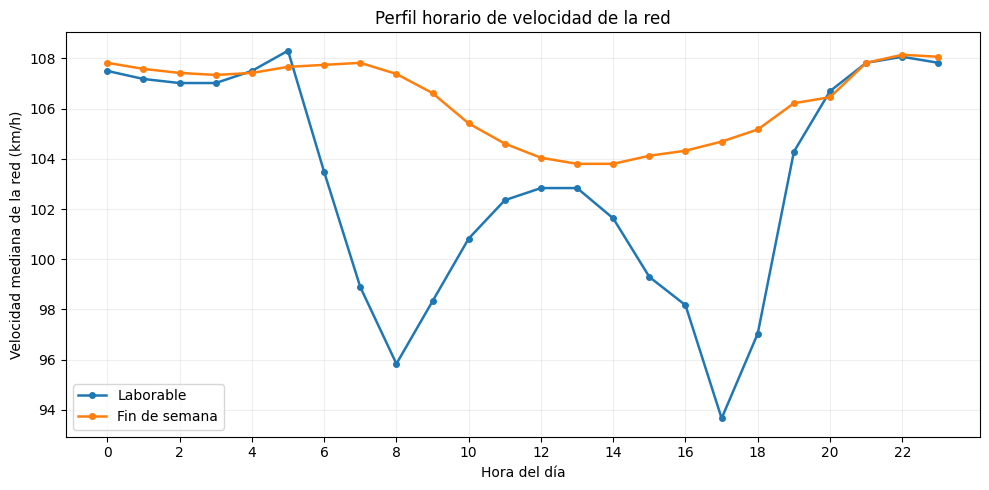

In [ ]:
# ------------------------------------------------------------
# 2.3.2 Perfil horario de velocidad de la red
# ------------------------------------------------------------

# Velocidad representativa de la red en cada instante:
# mediana entre las 345 aristas.
network_speed = edge_speeds_kmh.median(axis=1)

temporal_profile = pd.DataFrame(
    {
        'speed_kmh': network_speed
    },
    index=edge_speeds_kmh.index
)

# Variables temporales
temporal_profile['hour'] = temporal_profile.index.hour

temporal_profile['day_type'] = np.where(
    temporal_profile.index.dayofweek < 5,
    'Laborable',
    'Fin de semana'
)

# ------------------------------------------------------------
# Perfil horario
# ------------------------------------------------------------

hourly_profile = (
    temporal_profile
    .groupby(['day_type', 'hour'])['speed_kmh']
    .agg(['median', 'mean', 'count'])
    .reset_index()
)

# ------------------------------------------------------------
# Figura
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(10, 5)
)

for day_type in ['Laborable', 'Fin de semana']:

    data = hourly_profile.loc[
        hourly_profile['day_type'] == day_type
    ]

    ax.plot(
        data['hour'],
        data['median'],
        marker='o',
        markersize=4,
        linewidth=1.8,
        label=day_type
    )

ax.set_xlabel('Hora del día')
ax.set_ylabel('Velocidad mediana de la red (km/h)')

ax.set_title(
    'Perfil horario de velocidad de la red'
)

ax.set_xticks(range(0, 24, 2))

ax.grid(
    alpha=0.2
)

ax.legend()

plt.tight_layout()
plt.show()

El perfil obtenido reproduce la estructura temporal observada previamente en los datos originales. Durante los días laborables aparecen nuevamente dos reducciones pronunciadas de velocidad, con mínimos alrededor de las 8:00 y las 17:00 horas, mientras que los fines de semana presentan una variación considerablemente más suave.

La correspondencia entre ambos análisis proporciona una verificación adicional de que la construcción de la red experimental y la transformación de velocidades a tiempos de recorrido no alteraron los principales patrones temporales presentes en PEMS-BAY. A partir de este punto, el análisis se concentra en la dimensión espacial de dichos cambios sobre la red de routing.

### 2.4 Variación espacial del tráfico en la red experimental

El análisis temporal mostró diferencias sustanciales entre días laborables y fines de semana. Por esta razón, la dimensión espacial del tráfico se analiza manteniendo esta separación, con el fin de evitar que los patrones característicos de congestión de los días laborables se diluyan al combinarse con el comportamiento más estable observado durante los fines de semana.

Para cada tipo de día se construye un estado representativo de la red en cinco horarios —06:00, 08:00, 12:00, 17:00 y 20:00— calculando, para cada arista, la mediana de las velocidades registradas a esa hora durante todos los días correspondientes del periodo de estudio.

Todos los mapas utilizan una misma escala absoluta de velocidad, de manera que los colores sean directamente comparables entre horarios y tipos de día. Los tonos rojizos representan velocidades menores y los tonos verdes velocidades mayores. La separación gráfica por sentido definida previamente se conserva únicamente para mejorar la legibilidad de los corredores dirigidos.

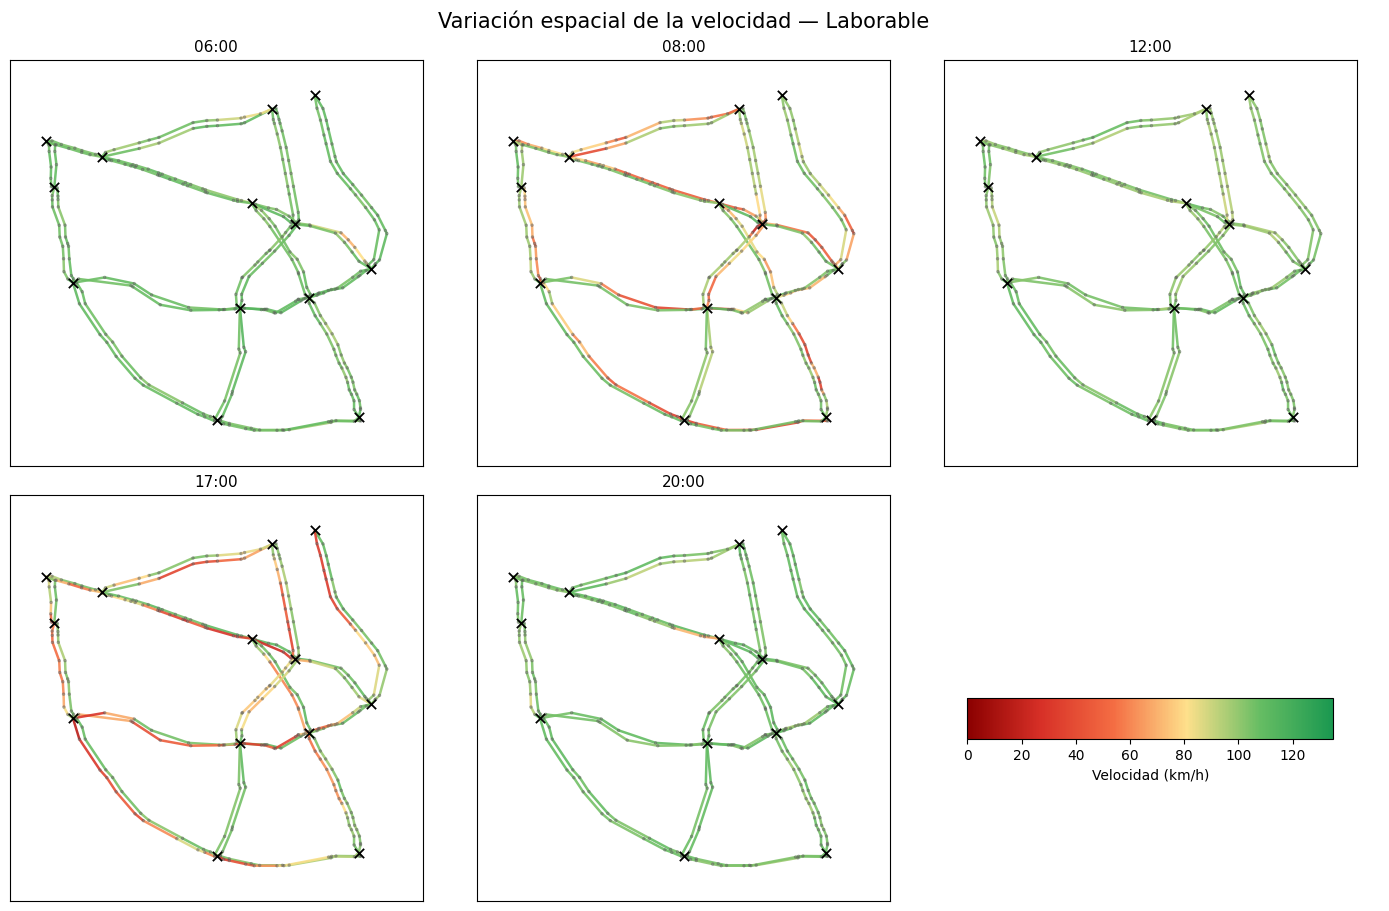

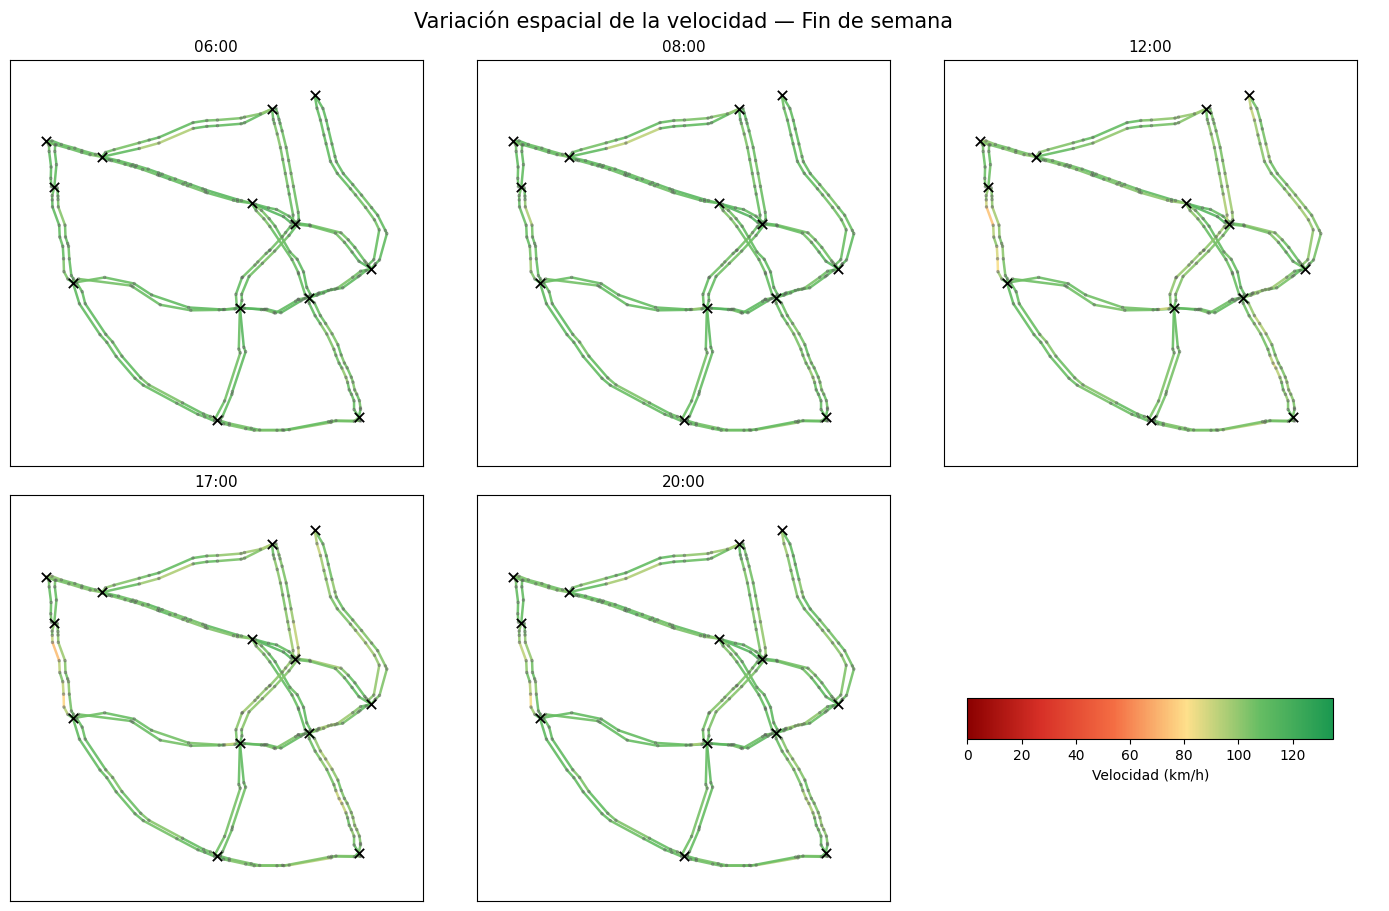

In [ ]:
# ------------------------------------------------------------
# 2.4 Variación espacial del tráfico en la red experimental
# ------------------------------------------------------------

import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

from matplotlib.colors import Normalize, LinearSegmentedColormap
from matplotlib.cm import ScalarMappable


# ------------------------------------------------------------
# Horarios de comparación
# ------------------------------------------------------------

selected_hours = [
    (6, 0),
    (8, 0),
    (12, 0),
    (17, 0),
    (20, 0)
]


# ------------------------------------------------------------
# Escala común de velocidad
#
# La misma escala se utiliza para todos los horarios y
# para días laborables y fines de semana.
# ------------------------------------------------------------

VMIN = 0
VMAX = 135


# ------------------------------------------------------------
# Paleta tipo tráfico
#
# Velocidades bajas  -> rojo
# Velocidades medias -> naranja / amarillo
# Velocidades altas  -> verde
# ------------------------------------------------------------

traffic_colors = [
    '#8b0000',  # rojo oscuro
    '#d73027',  # rojo
    '#f46d43',  # naranja
    '#fee08b',  # amarillo
    '#66bd63',  # verde claro
    '#1a9850'   # verde
]

cmap = LinearSegmentedColormap.from_list(
    'traffic_like',
    traffic_colors,
    N=256
)

norm = Normalize(
    vmin=VMIN,
    vmax=VMAX
)


# ------------------------------------------------------------
# Velocidad representativa por arista
#
# Para cada horario se calcula la mediana de cada arista
# considerando todos los días del mismo tipo.
# ------------------------------------------------------------

def representative_edge_speeds(
    day_type,
    hour,
    minute=0
):

    idx = edge_speeds_kmh.index

    time_mask = (
        (idx.hour == hour)
        & (idx.minute == minute)
    )

    if day_type == 'Laborable':

        day_mask = (
            idx.dayofweek < 5
        )

    elif day_type == 'Fin de semana':

        day_mask = (
            idx.dayofweek >= 5
        )

    else:

        raise ValueError(
            "day_type debe ser "
            "'Laborable' o 'Fin de semana'."
        )

    subset = edge_speeds_kmh.loc[
        time_mask & day_mask
    ]

    assert len(subset) > 0

    return (
        subset.median(axis=0),
        len(subset)
    )


# ------------------------------------------------------------
# Estados representativos
# ------------------------------------------------------------

representative_states = {}

for day_type in [
    'Laborable',
    'Fin de semana'
]:

    representative_states[
        day_type
    ] = {}

    for hour, minute in selected_hours:

        label = (
            f'{hour:02d}:{minute:02d}'
        )

        speeds, n_obs = (
            representative_edge_speeds(
                day_type,
                hour,
                minute
            )
        )

        representative_states[
            day_type
        ][label] = {
            'speeds': speeds,
            'n_obs': n_obs
        }


# ------------------------------------------------------------
# Sensores
# ------------------------------------------------------------

sensor_nodes = (
    nodes.loc[
        nodes['node_type'] == 'sensor',
        'node_id'
    ]
    .astype(str)
    .tolist()
)

sensor_xy = np.array([
    pos_shifted[node]
    for node in sensor_nodes
])


# ------------------------------------------------------------
# Macronodos
# ------------------------------------------------------------

interchange_nodes = (
    nodes.loc[
        nodes['node_type'] == 'interchange',
        'node_id'
    ]
    .astype(str)
    .tolist()
)

macro_xy = np.array([
    pos_shifted[node]
    for node in interchange_nodes
])


# ------------------------------------------------------------
# Aristas
#
# Se conserva el orden de edges, que coincide con las
# columnas de edge_speeds_kmh.
# ------------------------------------------------------------

plot_edges = list(
    zip(
        edges['from'].astype(str),
        edges['to'].astype(str)
    )
)


# ------------------------------------------------------------
# Corrección de proporción geográfica
# ------------------------------------------------------------

mean_lat = (
    nodes['latitude'].mean()
)


# ------------------------------------------------------------
# Función de visualización
# ------------------------------------------------------------

def plot_spatial_profiles(
    day_type
):

    fig, axes = plt.subplots(
        2,
        3,
        figsize=(14, 9),
        constrained_layout=True
    )

    axes = axes.ravel()


    # --------------------------------------------------------
    # Cinco horarios
    # --------------------------------------------------------

    for ax, (hour, minute) in zip(
        axes[:5],
        selected_hours
    ):

        label = (
            f'{hour:02d}:{minute:02d}'
        )

        speeds = (
            representative_states[
                day_type
            ][label]['speeds']
            .reindex(
                edges['edge_id']
            )
            .to_numpy()
        )


        # ----------------------------------------------------
        # Aristas coloreadas por velocidad
        # ----------------------------------------------------

        nx.draw_networkx_edges(
            G_view,
            pos_shifted,
            edgelist=plot_edges,
            ax=ax,
            arrows=False,
            width=1.8,
            alpha=0.90,
            edge_color=speeds,
            edge_cmap=cmap,
            edge_vmin=VMIN,
            edge_vmax=VMAX
        )


        # ----------------------------------------------------
        # Sensores
        #
        # Se representan en gris para no competir con
        # la escala de velocidad.
        # ----------------------------------------------------

        ax.scatter(
            sensor_xy[:, 0],
            sensor_xy[:, 1],
            s=6,
            color='0.35',
            edgecolors='none',
            alpha=0.50,
            zorder=3
        )


        # ----------------------------------------------------
        # Macronodos
        # ----------------------------------------------------

        ax.scatter(
            macro_xy[:, 0],
            macro_xy[:, 1],
            s=45,
            marker='x',
            color='black',
            linewidths=1.3,
            zorder=4
        )


        # ----------------------------------------------------
        # Formato
        # ----------------------------------------------------

        ax.set_title(
            label,
            fontsize=11
        )

        ax.set_aspect(
            1 / np.cos(
                np.deg2rad(
                    mean_lat
                )
            )
        )

        ax.set_xticks([])
        ax.set_yticks([])


    # --------------------------------------------------------
    # Sexto panel:
    # escala de velocidad
    # --------------------------------------------------------

    info_ax = axes[5]

    info_ax.axis('off')


    # Barra de color
    cax = info_ax.inset_axes(
        [
            0.10,
            0.40,
            0.80,
            0.10
        ]
    )

    sm = ScalarMappable(
        norm=norm,
        cmap=cmap
    )

    sm.set_array([])

    cbar = fig.colorbar(
        sm,
        cax=cax,
        orientation='horizontal'
    )

    cbar.set_label(
        'Velocidad (km/h)'
    )


    # --------------------------------------------------------
    # Título general
    # --------------------------------------------------------

    fig.suptitle(
        (
            'Variación espacial de la velocidad — '
            f'{day_type}'
        ),
        fontsize=15
    )

    plt.show()


# ------------------------------------------------------------
# Días laborables
# ------------------------------------------------------------

plot_spatial_profiles(
    'Laborable'
)


# ------------------------------------------------------------
# Fines de semana
# ------------------------------------------------------------

plot_spatial_profiles(
    'Fin de semana'
)

La comparación espacial confirma que la dinámica del tráfico no sólo varía con la hora del día, sino también con la localización y el sentido de circulación dentro de la red. En los días laborables, las reducciones de velocidad se concentran principalmente alrededor de las 08:00 y las 17:00 horas, mientras que a las 06:00, 12:00 y 20:00 la mayor parte de la red presenta velocidades relativamente altas. El deterioro observado durante la tarde parece además más extendido espacialmente que el correspondiente a la hora pico matutina, en concordancia con el perfil horario agregado obtenido previamente.

Las figuras muestran también que los dos sentidos de una misma autopista pueden presentar condiciones distintas en un mismo momento. En varios corredores se aprecia que el sentido con mayores reducciones de velocidad durante la mañana no coincide con el más afectado durante la tarde, lo que sugiere una inversión del patrón direccional entre ambas horas pico. Esta observación indica que la información agregada a nivel de autopista puede ocultar diferencias relevantes entre sentidos y respalda la conservación de la direccionalidad de las aristas en los análisis posteriores.

En contraste, durante los fines de semana las cinco instantáneas presentan una estructura espacial considerablemente más estable. Aunque persisten algunas reducciones localizadas de velocidad, no se observa una reorganización espacial tan marcada como la registrada en los días laborables. Esto refuerza la relevancia conjunta de la hora del día, el tipo de día y la localización dentro de la red para caracterizar su estado.

#### 2.4.1 Comportamiento por corredor y sentido

La inspección espacial sugiere que las reducciones de velocidad durante las horas pico presentan un componente direccional y que, en varios corredores, el sentido más afectado durante la mañana difiere del más afectado durante la tarde. Para verificar esta observación de manera cuantitativa, se resume la velocidad mediana de cada corredor dirigido en los cinco horarios analizados para días laborables.

Dado que distintos corredores pueden presentar niveles de velocidad estructuralmente diferentes, la intensidad de la reducción se expresa también respecto de una velocidad de referencia propia de cada corredor. Esta referencia corresponde al mayor valor mediano observado entre las 06:00, 12:00 y 20:00 horas. A partir de ella se calcula la reducción porcentual registrada a las 08:00 y 17:00 horas.

In [ ]:
# ------------------------------------------------------------
# 2.4.1 Comportamiento por corredor y sentido
# ------------------------------------------------------------

# Horarios utilizados
time_labels = [
    '06:00',
    '08:00',
    '12:00',
    '17:00',
    '20:00'
]


# ------------------------------------------------------------
# Velocidad mediana por corredor dirigido
# ------------------------------------------------------------

corridor_records = []

corridors = sorted(
    edges['corridor']
    .dropna()
    .astype(str)
    .unique()
)

for corridor in corridors:

    corridor_edge_ids = (
        edges.loc[
            edges['corridor'].astype(str) == corridor,
            'edge_id'
        ]
        .astype(str)
        .tolist()
    )

    record = {
        'corridor': corridor
    }

    for label in time_labels:

        speeds = (
            representative_states[
                'Laborable'
            ][label]['speeds']
            .reindex(corridor_edge_ids)
        )

        record[label] = speeds.median()

    corridor_records.append(record)


corridor_profile = pd.DataFrame(
    corridor_records
)


# ------------------------------------------------------------
# Autopista física y sentido
# ------------------------------------------------------------

corridor_profile[
    ['freeway', 'direction']
] = (
    corridor_profile['corridor']
    .str.split('-', n=1, expand=True)
)


# ------------------------------------------------------------
# Velocidad de referencia
#
# Se toma el mayor valor entre los horarios no pico
# seleccionados: 06:00, 12:00 y 20:00.
# ------------------------------------------------------------

corridor_profile[
    'reference_speed'
] = (
    corridor_profile[
        ['06:00', '12:00', '20:00']
    ]
    .max(axis=1)
)


# ------------------------------------------------------------
# Reducción porcentual en horas pico
# ------------------------------------------------------------

corridor_profile[
    'drop_08_pct'
] = (
    100
    * (
        corridor_profile['reference_speed']
        - corridor_profile['08:00']
    )
    / corridor_profile['reference_speed']
)

corridor_profile[
    'drop_17_pct'
] = (
    100
    * (
        corridor_profile['reference_speed']
        - corridor_profile['17:00']
    )
    / corridor_profile['reference_speed']
)


# ------------------------------------------------------------
# Orden
# ------------------------------------------------------------

corridor_profile['freeway_num'] = (
    corridor_profile['freeway']
    .astype(int)
)

corridor_profile = (
    corridor_profile
    .sort_values(
        ['freeway_num', 'direction']
    )
    .drop(columns='freeway_num')
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# Tabla por corredor
# ------------------------------------------------------------

corridor_table = corridor_profile[
    [
        'corridor',
        '06:00',
        '08:00',
        '12:00',
        '17:00',
        '20:00',
        'reference_speed',
        'drop_08_pct',
        'drop_17_pct'
    ]
].copy()

corridor_table = corridor_table.rename(
    columns={
        'corridor': 'Corredor',
        'reference_speed': 'Referencia',
        'drop_08_pct': 'Caída 08:00 (%)',
        'drop_17_pct': 'Caída 17:00 (%)'
    }
)

display(
    corridor_table.round(1)
)


# ------------------------------------------------------------
# Comparación entre sentidos de una misma autopista
#
# Se identifica el sentido con mayor reducción relativa
# en cada hora pico.
# ------------------------------------------------------------

directional_records = []

for freeway, group in corridor_profile.groupby(
    'freeway'
):

    if len(group) != 2:
        continue

    morning_idx = (
        group['drop_08_pct']
        .idxmax()
    )

    afternoon_idx = (
        group['drop_17_pct']
        .idxmax()
    )

    morning_corridor = (
        corridor_profile.loc[
            morning_idx,
            'corridor'
        ]
    )

    afternoon_corridor = (
        corridor_profile.loc[
            afternoon_idx,
            'corridor'
        ]
    )

    directional_records.append(
        {
            'Autopista': freeway,
            'Más afectado 08:00':
                morning_corridor,
            'Caída 08:00 (%)':
                corridor_profile.loc[
                    morning_idx,
                    'drop_08_pct'
                ],
            'Más afectado 17:00':
                afternoon_corridor,
            'Caída 17:00 (%)':
                corridor_profile.loc[
                    afternoon_idx,
                    'drop_17_pct'
                ],
            'Cambio de sentido':
                morning_corridor
                != afternoon_corridor
        }
    )


directional_summary = pd.DataFrame(
    directional_records
)

directional_summary[
    'Autopista_num'
] = (
    directional_summary[
        'Autopista'
    ]
    .astype(int)
)

directional_summary = (
    directional_summary
    .sort_values('Autopista_num')
    .drop(columns='Autopista_num')
    .reset_index(drop=True)
)

display(
    directional_summary.round(1)
)

,Corredor,06:00,08:00,12:00,17:00,20:00,Referencia,Caída 08:00 (%),Caída 17:00 (%)
0,17-N,110.2,95.6,102.4,105.0,108.4,110.2,13.2,4.7
1,17-S,104.9,101.3,101.9,103.2,106.6,106.6,4.9,3.1
2,85-N,105.9,61.0,104.4,103.8,106.2,106.2,42.6,2.3
3,85-S,106.5,105.4,105.5,58.7,103.8,106.5,1.1,44.9
4,87-N,103.6,73.9,103.6,103.6,105.7,105.7,30.1,2.1
5,87-S,106.0,103.8,104.1,67.4,103.4,106.0,2.0,36.4
6,101-N,103.9,56.3,102.5,106.4,107.1,107.1,47.4,0.7
7,101-S,106.4,104.3,99.9,64.9,104.5,106.4,1.9,39.1
8,237-E,108.5,97.3,99.3,58.0,97.5,108.5,10.3,46.5
9,237-W,98.7,66.9,101.5,89.4,106.0,106.0,36.9,15.7


,Autopista,Más afectado 08:00,Caída 08:00 (%),Más afectado 17:00,Caída 17:00 (%),Cambio de sentido
0,17,17-N,13.2,17-N,4.7,False
1,85,85-N,42.6,85-S,44.9,True
2,87,87-N,30.1,87-S,36.4,True
3,101,101-N,47.4,101-S,39.1,True
4,237,237-W,36.9,237-E,46.5,True
5,280,280-N,31.4,280-S,53.9,True
6,680,680-N,12.5,680-S,47.7,True
7,880,880-N,21.6,880-S,26.3,True


#### 2.4.2 Verificación cuantitativa del patrón direccional

El análisis por corredor confirma que las diferencias observadas visualmente entre ambos sentidos de circulación son sustanciales. En siete de las ocho autopistas físicas, el sentido con mayor reducción relativa de velocidad a las 08:00 difiere del más afectado a las 17:00. En las autopistas con orientación norte-sur, el deterioro matutino se concentra predominantemente en el sentido norte, mientras que durante la tarde se desplaza hacia el sentido sur. En la autopista 237 se observa un comportamiento análogo entre los sentidos oeste y este.

Las magnitudes de estas diferencias son relevantes. Por ejemplo, en la autopista 101 la velocidad mediana del corredor 101-N disminuye 47.4 % respecto de su referencia a las 08:00, mientras que 101-S sólo presenta una reducción de 1.9 %. A las 17:00 el patrón se invierte: 101-S registra una reducción de 39.1 %, frente a apenas 0.7 % en 101-N. Comportamientos similares se observan en las autopistas 85, 87, 280 y 680.

La autopista 17 constituye la principal excepción, ya que 17-N permanece como el sentido relativamente más afectado en ambos horarios; sin embargo, la reducción vespertina es moderada en comparación con los demás corredores. En conjunto, estos resultados respaldan la interpretación de que la dinámica del tráfico presenta un fuerte componente direccional y que el estado de una autopista no puede representarse adecuadamente mediante una única condición agregada para ambos sentidos.

Esta evidencia es relevante para las etapas posteriores del proyecto, ya que muestra que la información contenida en distintos pares origen-destino no es necesariamente equivalente y motiva analizar posteriormente qué entradas de la matriz resultan más informativas para su reconstrucción a partir de un número reducido de observaciones actuales.

En conjunto, los resultados muestran que el estado del tráfico es espacialmente heterogéneo y direccional. Esta característica es especialmente relevante para las etapas posteriores del proyecto, ya que sugiere que, cuando sólo se disponga de un número reducido de observaciones actuales de la matriz de tiempos de viaje, la elección de los pares origen-destino observados puede ser tan importante como la cantidad de observaciones disponibles.

## 3. Construcción del dataset de matrices de tiempos de viaje

El dataset recibido de la Notebook 1 contiene, para cada instante, los tiempos de recorrido de las 345 aristas de la red experimental. Para las etapas posteriores del proyecto, el objeto de interés no es cada arista de manera aislada, sino la matriz de tiempos mínimos de viaje entre los nodos utilizados por la capa de ruteo.

Para cada instante $t$ se define

$$
T_{\mathrm{ref}}(t)=\operatorname{SP}\left(G,\tau(t)\right),
$$

donde $\tau(t)$ contiene los tiempos observados de las aristas y $\operatorname{SP}$ representa el cálculo de caminos de tiempo mínimo sobre la red dirigida.

Considerando los 13 macronodos, cada instante produce una matriz dirigida de $13\times13$. La secuencia completa de estas matrices constituye un tensor temporal

$$
\mathcal{T}\in\mathbb{R}^{N\times13\times13},
$$

donde $N$ corresponde al número de instantes disponibles. Las 13 entradas diagonales son iguales a cero por definición; por ello, para el modelado y la evaluación se utilizan los 156 pares origen-destino no diagonales.

En esta etapa se utiliza una aproximación *snapshot*: para construir $T_{\mathrm{ref}}(t)$, los tiempos de todas las aristas se fijan en los valores correspondientes al instante $t$ durante todo el cálculo de caminos mínimos. Por tanto, la matriz representa el estado de la red en ese instante y no modela todavía la evolución de los tiempos de las aristas durante el recorrido. Esta simplificación permite aislar primero el problema de reconstrucción de la matriz antes de introducir extensiones estrictamente dependientes del tiempo.

### 3.1 Construcción de matrices origen-destino

Para esta etapa se utilizan como nodos origen-destino los 13 macronodos definidos en la red experimental. De esta manera, cada instante genera una matriz dirigida de $13\times13$, equivalente a 156 pares origen-destino no diagonales.

Se implementa una función que recibe un vector de tiempos de las 345 aristas y devuelve la matriz correspondiente de tiempos mínimos. La topología de la red permanece fija y únicamente cambian los pesos de las aristas.

In [ ]:
# ------------------------------------------------------------
# 3.1 Construcción de matrices origen-destino
# ------------------------------------------------------------

from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import dijkstra


# ------------------------------------------------------------
# Nodos del grafo
# ------------------------------------------------------------

graph_nodes = (
    nodes['node_id']
    .astype(str)
    .tolist()
)

node_to_idx = {
    node: i
    for i, node in enumerate(graph_nodes)
}


# ------------------------------------------------------------
# Macronodos utilizados como nodos OD
# ------------------------------------------------------------

routing_nodes = sorted(
    nodes.loc[
        nodes['node_type'] == 'interchange',
        'node_id'
    ]
    .astype(str)
    .tolist()
)

assert len(routing_nodes) == 13

routing_idx = np.array([
    node_to_idx[node]
    for node in routing_nodes
])


# ------------------------------------------------------------
# Índices de origen y destino de las 345 aristas
# ------------------------------------------------------------

edge_from_idx = (
    edges['from']
    .astype(str)
    .map(node_to_idx)
    .to_numpy()
)

edge_to_idx = (
    edges['to']
    .astype(str)
    .map(node_to_idx)
    .to_numpy()
)

assert not pd.isna(edge_from_idx).any()
assert not pd.isna(edge_to_idx).any()


# La representación debe contener como máximo una arista
# dirigida para cada par ordenado de nodos.
assert not edges.duplicated(
    subset=['from', 'to']
).any()


# ------------------------------------------------------------
# Función de matriz OD a partir de tiempos de arista
# ------------------------------------------------------------

def travel_time_matrix_from_edges(
    edge_times
):
    """
    Construye la matriz dirigida de tiempos mínimos entre
    los 13 macronodos a partir de los tiempos de las 345
    aristas de la red.

    Parameters
    ----------
    edge_times : pd.Series o array-like
        Tiempo de recorrido de cada arista en minutos.

    Returns
    -------
    pd.DataFrame
        Matriz 13 x 13 de tiempos mínimos de viaje.
    """

    # Si se recibe una Series, alinear explícitamente
    # por edge_id.
    if isinstance(
        edge_times,
        pd.Series
    ):

        weights = (
            edge_times
            .reindex(
                edges['edge_id']
            )
            .to_numpy(
                dtype=float
            )
        )

    else:

        weights = np.asarray(
            edge_times,
            dtype=float
        )

        assert (
            len(weights)
            == len(edges)
        )


    # Validaciones
    assert np.isfinite(
        weights
    ).all()

    assert (
        weights > 0
    ).all()


    # Grafo dirigido disperso
    G_sparse = csr_matrix(
        (
            weights,
            (
                edge_from_idx,
                edge_to_idx
            )
        ),
        shape=(
            len(graph_nodes),
            len(graph_nodes)
        )
    )


    # Dijkstra desde los 13 macronodos
    distances = dijkstra(
        G_sparse,
        directed=True,
        indices=routing_idx,
        return_predecessors=False
    )


    # Conservar únicamente destinos macronodo
    T = distances[
        :,
        routing_idx
    ]


    return pd.DataFrame(
        T,
        index=routing_nodes,
        columns=routing_nodes
    )

### 3.2 Validación sobre un instante

Antes de generar la secuencia completa de matrices se verifica el procedimiento sobre un único instante del dataset. La matriz resultante debe ser finita, dirigida, de dimensión $13\times13$ y presentar diagonal nula.

In [ ]:
# ------------------------------------------------------------
# Validación sobre un instante
# ------------------------------------------------------------

check_timestamp = (
    edge_travel_times.index[0]
)

check_edge_times = (
    edge_travel_times.loc[
        check_timestamp
    ]
)

T_check = (
    travel_time_matrix_from_edges(
        check_edge_times
    )
)


# ------------------------------------------------------------
# Validaciones básicas
# ------------------------------------------------------------

assert T_check.shape == (
    13,
    13
)

assert np.isfinite(
    T_check.to_numpy()
).all()

assert np.allclose(
    np.diag(
        T_check.to_numpy()
    ),
    0.0
)

assert (
    T_check.to_numpy()
    >= 0
).all()


print(
    'Timestamp:',
    check_timestamp
)

print(
    'Dimensión:',
    T_check.shape
)

print(
    'Valores no finitos:',
    np.sum(
        ~np.isfinite(
            T_check.to_numpy()
        )
    )
)

print(
    'Máximo error en diagonal:',
    np.abs(
        np.diag(
            T_check.to_numpy()
        )
    ).max()
)

display(
    T_check.round(3)
)

Timestamp: 2017-01-01 00:00:00
Dimensión: (13, 13)
Valores no finitos: 0
Máximo error en diagonal: 0.0


,I00,I01,I02,I03,I04,I05,I06,I07,I08,I09,I10,I11,I12
I00,0.000,9.770,6.707,10.224,13.815,16.378,5.972,1.916,3.533,6.865,13.351,5.153,8.945
I01,9.916,0.000,3.096,4.811,8.892,6.608,7.068,11.831,13.449,10.766,6.717,4.727,2.311
I02,6.820,3.063,0.000,3.517,7.598,9.671,3.973,8.736,10.353,9.472,9.780,1.631,5.374
I03,10.378,4.765,3.558,0.000,4.081,11.373,7.531,10.930,9.296,5.955,6.865,5.189,2.458
I04,13.841,8.791,7.584,4.025,0.000,15.399,11.556,11.941,10.307,6.965,4.838,9.215,6.484
I05,16.639,6.723,9.819,11.534,15.615,0.000,13.791,18.555,20.172,17.489,13.440,11.450,9.034
I06,6.025,6.964,3.901,7.418,11.499,13.572,0.000,7.941,9.558,12.890,13.681,5.532,9.274
I07,1.900,11.670,8.607,10.844,11.900,18.278,7.872,0.000,1.617,4.949,15.251,7.053,10.845
I08,3.534,13.304,10.241,9.227,10.282,19.912,9.507,1.634,0.000,3.332,15.120,8.687,11.686
I09,6.875,10.661,9.453,5.895,6.951,17.269,12.848,4.975,3.341,0.000,11.788,11.085,8.354


### 3.3 Validación de la implementación

Antes de utilizar la implementación basada en matrices dispersas para procesar todos los instantes del experimento, se verifica su equivalencia con el cálculo de caminos mínimos mediante NetworkX utilizado en la Notebook 1. Ambas implementaciones reciben exactamente los mismos tiempos por arista y deben producir la misma matriz origen-destino, salvo diferencias numéricas atribuibles a precisión de punto flotante.

In [ ]:
# ------------------------------------------------------------
# Validación SciPy vs. NetworkX
# ------------------------------------------------------------

# Tiempos del mismo instante utilizados en la prueba anterior
check_weights = (
    check_edge_times
    .reindex(edges['edge_id'])
    .to_numpy(dtype=float)
)


# ------------------------------------------------------------
# Construcción del grafo NetworkX
# ------------------------------------------------------------

G_check = nx.DiGraph()

G_check.add_nodes_from(
    graph_nodes
)

for (_, row), weight in zip(
    edges.iterrows(),
    check_weights
):

    G_check.add_edge(
        str(row['from']),
        str(row['to']),
        travel_time_min=float(weight)
    )


# ------------------------------------------------------------
# Matriz OD mediante NetworkX
# ------------------------------------------------------------

T_nx = pd.DataFrame(
    np.inf,
    index=routing_nodes,
    columns=routing_nodes,
    dtype=float
)

np.fill_diagonal(
    T_nx.values,
    0.0
)

for origin in routing_nodes:

    lengths = (
        nx.single_source_dijkstra_path_length(
            G_check,
            source=origin,
            weight='travel_time_min'
        )
    )

    for destination in routing_nodes:

        if destination in lengths:

            T_nx.loc[
                origin,
                destination
            ] = lengths[destination]


# ------------------------------------------------------------
# Comparación con implementación SciPy
# ------------------------------------------------------------

difference = (
    T_check.to_numpy()
    - T_nx.to_numpy()
)

max_abs_difference = np.max(
    np.abs(difference)
)

assert np.allclose(
    T_check.to_numpy(),
    T_nx.to_numpy(),
    rtol=1e-10,
    atol=1e-12
)

print(
    'Las implementaciones son equivalentes.'
)

print(
    'Diferencia absoluta máxima:',
    f'{max_abs_difference:.3e} min'
)

Las implementaciones son equivalentes.
Diferencia absoluta máxima: 0.000e+00 min


### 3.4 Construcción del tensor temporal

Una vez validado el procedimiento, se calcula $T_{\mathrm{ref}}(t)$ para cada uno de los instantes disponibles en el dataset. Cada matriz utiliza los tiempos observados de las 345 aristas en el instante correspondiente y contiene los tiempos mínimos de viaje entre los 13 macronodos.

Al apilar las matrices se obtiene un tensor de dimensión $N\times13\times13$, donde $N$ es el número de observaciones temporales. Esta representación conserva explícitamente la estructura matricial del problema y constituirá el punto de partida tanto para el baseline histórico $K=0$ como para los métodos posteriores de reconstrucción con observaciones parciales $K>0$.

In [ ]:
# ------------------------------------------------------------
# 3.4 Construcción del tensor temporal
# ------------------------------------------------------------

from time import perf_counter


# ------------------------------------------------------------
# Máscara de pares OD no diagonales
# ------------------------------------------------------------

od_mask = ~np.eye(
    len(routing_nodes),
    dtype=bool
)

N_OD = od_mask.sum()

assert N_OD == 13 * 12


# ------------------------------------------------------------
# Transformación de una serie temporal de tiempos por arista
# en una secuencia de matrices OD
# ------------------------------------------------------------

def build_od_matrices(
    edge_time_array
):
    """
    Convierte una matriz temporal de tiempos por arista
    (n_instantes x 345) en matrices OD entre los
    13 macronodos.

    Returns
    -------
    np.ndarray
        Tensor de dimensión:
        n_instantes x 13 x 13
    """

    edge_time_array = np.asarray(
        edge_time_array,
        dtype=float
    )

    assert edge_time_array.ndim == 2

    assert (
        edge_time_array.shape[1]
        == len(edges)
    )

    n_times = edge_time_array.shape[0]

    matrices = np.empty(
        (
            n_times,
            len(routing_nodes),
            len(routing_nodes)
        ),
        dtype=float
    )

    for i in range(n_times):

        matrices[i] = (
            travel_time_matrix_from_edges(
                edge_time_array[i]
            )
            .to_numpy()
        )

    return matrices


# ------------------------------------------------------------
# Construcción de T_ref(t) para todo el periodo
# ------------------------------------------------------------

start = perf_counter()

T_all = build_od_matrices(
    edge_travel_times.to_numpy()
)

elapsed = (
    perf_counter()
    - start
)


# ------------------------------------------------------------
# Validaciones
# ------------------------------------------------------------

assert T_all.shape == (
    len(edge_travel_times),
    13,
    13
)

assert np.isfinite(
    T_all
).all()

assert np.allclose(
    np.diagonal(
        T_all,
        axis1=1,
        axis2=2
    ),
    0.0
)

assert (
    T_all >= 0
).all()


# ------------------------------------------------------------
# Resumen
# ------------------------------------------------------------

print(
    'Tensor temporal construido:',
    T_all.shape
)

print(
    'Pares OD no diagonales:',
    N_OD
)

print(
    'Periodo:',
    edge_travel_times.index.min(),
    '→',
    edge_travel_times.index.max()
)

print(
    'Tiempo total de construcción:',
    f'{elapsed:.2f} s'
)

print(
    'Tiempo medio por matriz:',
    f'{1000 * elapsed / len(edge_travel_times):.2f} ms'
)

Tensor temporal construido: (52116, 13, 13)
Pares OD no diagonales: 156
Periodo: 2017-01-01 00:00:00 → 2017-06-30 23:55:00
Tiempo total de construcción: 45.09 s
Tiempo medio por matriz: 0.87 ms


### 3.5 Representación para modelado

La representación tensorial $T_{\mathrm{ref}}(t)$ conserva la estructura natural de la matriz origen-destino y será especialmente útil para los métodos posteriores de reconstrucción parcial. Sin embargo, las entradas diagonales son siempre iguales a cero y no contienen información predictiva.

Por esta razón se construye también una representación tabular equivalente que conserva únicamente los 156 pares origen-destino dirigidos no diagonales. Cada fila representa un instante y cada columna un par ordenado $(i,j)$. Esta representación facilita la construcción y evaluación del baseline histórico sin modificar la información contenida en las matrices originales.

In [ ]:
# ------------------------------------------------------------
# 3.5 Representación tabular para modelado
# ------------------------------------------------------------

od_pairs = [
    (origin, destination)
    for origin in routing_nodes
    for destination in routing_nodes
    if origin != destination
]

assert len(od_pairs) == N_OD


# ------------------------------------------------------------
# Columnas con estructura origen-destino
# ------------------------------------------------------------

od_columns = pd.MultiIndex.from_tuples(
    od_pairs,
    names=[
        'origin',
        'destination'
    ]
)


# ------------------------------------------------------------
# Tensor -> tabla temporal de pares OD
# ------------------------------------------------------------

od_times = pd.DataFrame(
    T_all[:, od_mask],
    index=edge_travel_times.index,
    columns=od_columns
)

od_times.index.name = 'timestamp'


# ------------------------------------------------------------
# Validaciones
# ------------------------------------------------------------

assert od_times.shape == (
    len(edge_travel_times),
    156
)

assert np.isfinite(
    od_times.to_numpy()
).all()

assert (
    od_times.to_numpy() > 0
).all()


# ------------------------------------------------------------
# Resumen
# ------------------------------------------------------------

print(
    'Dataset OD construido:',
    od_times.shape
)

print(
    'Periodo:',
    od_times.index.min(),
    '→',
    od_times.index.max()
)

print()
print(
    'Primeros pares OD:'
)

print(
    od_times.columns[:8].tolist()
)

display(
    od_times.iloc[:5, :8].round(3)
)

Dataset OD construido: (52116, 156)
Periodo: 2017-01-01 00:00:00 → 2017-06-30 23:55:00

Primeros pares OD:
[('I00', 'I01'), ('I00', 'I02'), ('I00', 'I03'), ('I00', 'I04'), ('I00', 'I05'), ('I00', 'I06'), ('I00', 'I07'), ('I00', 'I08')]


origin                 I00                                                    
destination            I01    I02     I03     I04     I05    I06    I07    I08
timestamp                                                                     
2017-01-01 00:00:00  9.770  6.707  10.224  13.815  16.378  5.972  1.916  3.533
2017-01-01 00:05:00  9.805  6.731  10.248  13.872  16.438  6.012  1.926  3.543
2017-01-01 00:10:00  9.817  6.741  10.264  13.876  16.461  6.004  1.922  3.539
2017-01-01 00:15:00  9.817  6.741  10.269  13.894  16.494  6.028  1.930  3.551
2017-01-01 00:20:00  9.835  6.756  10.293  13.911  16.513  6.020  1.930  3.546

## 4. División temporal del dataset origen-destino

La construcción y evaluación del baseline histórico debe preservar el orden temporal de las observaciones. Una partición aleatoria permitiría que información correspondiente a fechas futuras influyera en la estimación de instantes anteriores, produciendo fuga de información y una evaluación artificialmente optimista.

Por esta razón, el dataset de matrices de tiempos de viaje se divide cronológicamente en tres subconjuntos: enero–abril de 2017 para entrenamiento, mayo de 2017 para validación y junio de 2017 para prueba. El conjunto de entrenamiento se utiliza para construir las referencias históricas; el conjunto de validación permite comparar especificaciones y seleccionar el baseline $K=0$; y el conjunto de prueba permanece sin utilizar hasta la evaluación final.

La partición se aplica directamente a la representación tabular de los 156 pares origen-destino, manteniendo la correspondencia exacta con las matrices del tensor temporal.

In [ ]:
# ------------------------------------------------------------
# 4. División temporal del dataset OD
# ------------------------------------------------------------

train_od = od_times.loc[
    '2017-01-01':'2017-04-30 23:59:59'
].copy()

val_od = od_times.loc[
    '2017-05-01':'2017-05-31 23:59:59'
].copy()

test_od = od_times.loc[
    '2017-06-01':'2017-06-30 23:59:59'
].copy()


# ------------------------------------------------------------
# Validaciones
# ------------------------------------------------------------

assert len(train_od) + len(val_od) + len(test_od) == len(od_times)

assert train_od.index.max() < val_od.index.min()
assert val_od.index.max() < test_od.index.min()

assert train_od.columns.equals(od_times.columns)
assert val_od.columns.equals(od_times.columns)
assert test_od.columns.equals(od_times.columns)

assert np.isfinite(train_od.to_numpy()).all()
assert np.isfinite(val_od.to_numpy()).all()
assert np.isfinite(test_od.to_numpy()).all()

assert (train_od.to_numpy() > 0).all()
assert (val_od.to_numpy() > 0).all()
assert (test_od.to_numpy() > 0).all()


# ------------------------------------------------------------
# Resumen
# ------------------------------------------------------------

split_summary = pd.DataFrame({
    'Conjunto': [
        'Entrenamiento',
        'Validación',
        'Prueba'
    ],
    'Observaciones': [
        len(train_od),
        len(val_od),
        len(test_od)
    ],
    'Inicio': [
        train_od.index.min(),
        val_od.index.min(),
        test_od.index.min()
    ],
    'Fin': [
        train_od.index.max(),
        val_od.index.max(),
        test_od.index.max()
    ]
})

split_summary[
    'Porcentaje'
] = (
    100
    * split_summary['Observaciones']
    / len(od_times)
)

display(
    split_summary.style.format({
        'Porcentaje': '{:.2f}%'
    })
)

,Conjunto,Observaciones,Inicio,Fin,Porcentaje
0,Entrenamiento,34548,2017-01-01 00:00:00,2017-04-30 23:55:00,66.29%
1,Validación,8928,2017-05-01 00:00:00,2017-05-31 23:55:00,17.13%
2,Prueba,8640,2017-06-01 00:00:00,2017-06-30 23:55:00,16.58%


## 5. Baseline histórico $K=0$

El escenario $K=0$ representa la situación en la que no se dispone de ninguna observación actual de la matriz de tiempos de viaje. En consecuencia, cada entrada origen-destino debe estimarse exclusivamente a partir de información histórica disponible antes del instante evaluado.

Como primera aproximación se comparan tres referencias históricas de complejidad creciente: la media histórica de cada par origen-destino, la media condicionada por hora del día y la media condicionada conjuntamente por día de la semana y hora. En todos los casos cada uno de los 156 pares dirigidos conserva una estimación propia.

Los candidatos se construyen únicamente con el conjunto de entrenamiento y se evalúan sobre mayo de 2017. El conjunto de prueba permanece sin utilizar durante esta etapa.

### 5.1 Referencias históricas iniciales

Como primera evaluación se construyen tres referencias de complejidad creciente para cada par origen-destino: una media histórica no condicionada, una media condicionada por hora del día y una media condicionada conjuntamente por día de la semana y hora. La media histórica no condicionada se utiliza además como nivel mínimo de referencia: una especificación temporal sólo se considerará útil si mejora de forma clara su desempeño sobre el conjunto de validación.

In [ ]:
# ------------------------------------------------------------
# 5.1 Referencias históricas iniciales sobre pares OD
# ------------------------------------------------------------

# ------------------------------------------------------------
# Referencia 1: media histórica por par OD
# ------------------------------------------------------------

od_mean_global = (
    train_od
    .mean(axis=0)
)


# ------------------------------------------------------------
# Referencia 2: media por hora del día y par OD
# ------------------------------------------------------------

od_mean_hour = (
    train_od
    .groupby(
        train_od.index.hour
    )
    .mean()
)

od_mean_hour.index.name = 'hour'


# ------------------------------------------------------------
# Referencia 3: media por día de semana, hora y par OD
# ------------------------------------------------------------

od_mean_weekday_hour = (
    train_od
    .groupby([
        train_od.index.dayofweek,
        train_od.index.hour
    ])
    .mean()
)

od_mean_weekday_hour.index.names = [
    'dayofweek',
    'hour'
]


# ------------------------------------------------------------
# Validaciones
# ------------------------------------------------------------

assert od_mean_global.shape == (156,)
assert od_mean_hour.shape == (24, 156)
assert od_mean_weekday_hour.shape == (168, 156)

assert od_mean_global.index.equals(train_od.columns)
assert od_mean_hour.columns.equals(train_od.columns)
assert od_mean_weekday_hour.columns.equals(train_od.columns)

assert np.isfinite(
    od_mean_global.to_numpy()
).all()

assert np.isfinite(
    od_mean_hour.to_numpy()
).all()

assert np.isfinite(
    od_mean_weekday_hour.to_numpy()
).all()


print('Referencias históricas OD construidas correctamente.')
print()
print('Media histórica:', od_mean_global.shape)
print('Media por hora:', od_mean_hour.shape)
print('Media día de semana + hora:', od_mean_weekday_hour.shape)

Referencias históricas OD construidas correctamente.

Media histórica: (156,)
Media por hora: (24, 156)
Media día de semana + hora: (168, 156)


### 5.2 Evaluación inicial sobre el conjunto de validación

Las tres referencias históricas se utilizan para estimar directamente los 156 tiempos origen-destino durante mayo de 2017. Las predicciones se construyen exclusivamente con información del periodo de entrenamiento, por lo que ninguna observación del conjunto de validación interviene en su cálculo.

El desempeño se evalúa mediante MAE, RMSE y WAPE. El MAE se utiliza como métrica principal por su interpretación directa en unidades de tiempo; el RMSE complementa el análisis al penalizar con mayor intensidad las desviaciones grandes; y el WAPE proporciona una medida relativa del error agregado.

A diferencia de las evaluaciones exploratorias previas sobre tiempos por arista, estas métricas corresponden directamente al objeto de interés del proyecto: la matriz de tiempos de viaje entre macronodos.

In [ ]:
# ------------------------------------------------------------
# 5.2 Evaluación inicial sobre validación
# ------------------------------------------------------------

y_val_od = val_od.to_numpy()


# ------------------------------------------------------------
# Predicción 1: media histórica
# ------------------------------------------------------------

pred_od_global = np.tile(
    od_mean_global.to_numpy(),
    (len(val_od), 1)
)


# ------------------------------------------------------------
# Predicción 2: media por hora
# ------------------------------------------------------------

pred_od_hour = (
    od_mean_hour
    .reindex(
        val_od.index.hour
    )
    .to_numpy()
)


# ------------------------------------------------------------
# Predicción 3: día de semana + hora
# ------------------------------------------------------------

weekday_hour_keys = pd.MultiIndex.from_arrays(
    [
        val_od.index.dayofweek,
        val_od.index.hour
    ],
    names=[
        'dayofweek',
        'hour'
    ]
)

pred_od_weekday_hour = (
    od_mean_weekday_hour
    .reindex(
        weekday_hour_keys
    )
    .to_numpy()
)


# ------------------------------------------------------------
# Validaciones
# ------------------------------------------------------------

for pred in [
    pred_od_global,
    pred_od_hour,
    pred_od_weekday_hour
]:

    assert pred.shape == y_val_od.shape
    assert np.isfinite(pred).all()
    assert (pred > 0).all()


# ------------------------------------------------------------
# Métricas
# ------------------------------------------------------------

def regression_metrics(
    y_true,
    y_pred
):

    error = (
        y_pred - y_true
    )

    abs_error = np.abs(
        error
    )

    mae_min = (
        abs_error.mean()
    )

    rmse_min = np.sqrt(
        np.mean(
            error ** 2
        )
    )

    wape = (
        100
        * abs_error.sum()
        / np.abs(y_true).sum()
    )

    return {
        'MAE (min)': mae_min,
        'MAE (s)': 60 * mae_min,
        'RMSE (min)': rmse_min,
        'RMSE (s)': 60 * rmse_min,
        'WAPE (%)': wape
    }


# ------------------------------------------------------------
# Comparación
# ------------------------------------------------------------

od_validation_results = pd.DataFrame(
    {
        'Media histórica':
            regression_metrics(
                y_val_od,
                pred_od_global
            ),

        'Media por hora':
            regression_metrics(
                y_val_od,
                pred_od_hour
            ),

        'Día de semana + hora':
            regression_metrics(
                y_val_od,
                pred_od_weekday_hour
            )
    }
).T


# ------------------------------------------------------------
# Mejora respecto de la referencia más simple
# ------------------------------------------------------------

baseline_mae = (
    od_validation_results.loc[
        'Media histórica',
        'MAE (min)'
    ]
)

od_validation_results[
    'Mejora MAE vs. media (%)'
] = (
    100
    * (
        baseline_mae
        - od_validation_results[
            'MAE (min)'
        ]
    )
    / baseline_mae
)


display(
    od_validation_results.style.format({
        'MAE (min)': '{:.4f}',
        'MAE (s)': '{:.2f}',
        'RMSE (min)': '{:.4f}',
        'RMSE (s)': '{:.2f}',
        'WAPE (%)': '{:.2f}%',
        'Mejora MAE vs. media (%)': '{:.2f}%'
    })
)

,MAE (min),MAE (s),RMSE (min),RMSE (s),WAPE (%),Mejora MAE vs. media (%)
Media histórica,1.4173,85.04,2.6292,157.75,14.03%,0.00%
Media por hora,0.7687,46.12,1.7901,107.41,7.61%,45.76%
Día de semana + hora,0.4488,26.93,1.1369,68.21,4.44%,68.34%


Los resultados de validación muestran que la estructura temporal aporta una mejora sustancial en la estimación directa de la matriz de tiempos de viaje. La media histórica por par origen-destino obtiene un MAE de 85.04 s y un WAPE de 14.03 %. Al condicionar la estimación únicamente por hora del día, el MAE disminuye a 46.12 s, lo que representa una reducción de 45.76 % respecto de la referencia más simple. La incorporación conjunta del día de la semana y la hora produce una mejora adicional, reduciendo el MAE a 26.93 s y el WAPE a 4.44 %, equivalentes a una reducción de 68.34 % en el MAE respecto de la media histórica. El RMSE disminuye asimismo de 157.75 s a 68.21 s, lo que indica una reducción importante de las desviaciones de mayor magnitud. Estos resultados son consistentes con los patrones identificados durante el análisis exploratorio y confirman que el comportamiento histórico de cada par origen-destino presenta una estructura temporal recurrente que puede aprovecharse en el escenario $K=0$.

### 5.3 Granularidad temporal y estadístico histórico

La referencia condicionada por día de la semana y hora mostró el mejor desempeño entre las alternativas iniciales. Dado que el tensor temporal conserva la resolución nominal de cinco minutos del dataset original, se evalúa si una mayor granularidad temporal permite representar mejor las variaciones recurrentes de los tiempos origen-destino.

Se comparan cuatro resoluciones —60, 30, 15 y 5 minutos— condicionadas en todos los casos por el día de la semana. Para cada resolución se construyen dos referencias históricas para cada uno de los 156 pares origen-destino: la media y la mediana. Todos los candidatos se estiman exclusivamente con el conjunto de entrenamiento y se evalúan sobre mayo de 2017.

El MAE se utiliza como métrica principal de selección, mientras que RMSE y WAPE se emplean como métricas complementarias. También se registra el percentil 95 del error absoluto para caracterizar las desviaciones de mayor magnitud.

In [ ]:
# ------------------------------------------------------------
# 5.3 Granularidad temporal y estadístico histórico
# ------------------------------------------------------------

RESOLUTIONS = [
    60,
    30,
    15,
    5
]

STATISTICS = [
    'mean',
    'median'
]


# ------------------------------------------------------------
# Clave temporal:
# día de semana + intervalo dentro del día
# ------------------------------------------------------------

def temporal_keys(
    index,
    resolution_min
):

    assert 1440 % resolution_min == 0

    minute_of_day = (
        index.hour * 60
        + index.minute
    )

    slot = (
        minute_of_day
        // resolution_min
    )

    return pd.MultiIndex.from_arrays(
        [
            index.dayofweek,
            slot
        ],
        names=[
            'dayofweek',
            'slot'
        ]
    )


# ------------------------------------------------------------
# Construcción de referencia histórica OD
# ------------------------------------------------------------

def build_od_reference(
    train_df,
    resolution_min,
    statistic
):

    keys = temporal_keys(
        train_df.index,
        resolution_min
    )

    grouped = train_df.groupby(
        keys
    )

    if statistic == 'mean':

        reference = (
            grouped.mean()
        )

    elif statistic == 'median':

        reference = (
            grouped.median()
        )

    else:

        raise ValueError(
            "statistic debe ser "
            "'mean' o 'median'."
        )

    return reference


# ------------------------------------------------------------
# Predicción histórica OD
# ------------------------------------------------------------

def predict_od_reference(
    reference,
    target_df,
    resolution_min
):

    keys = temporal_keys(
        target_df.index,
        resolution_min
    )

    pred = (
        reference
        .reindex(keys)
        .to_numpy()
    )

    assert pred.shape == target_df.shape
    assert np.isfinite(pred).all()
    assert (pred > 0).all()

    return pred


# ------------------------------------------------------------
# Evaluación de candidatos
# ------------------------------------------------------------

candidate_results = []

y_val_od = (
    val_od.to_numpy()
)

for resolution in RESOLUTIONS:

    for statistic in STATISTICS:

        label_stat = (
            'Media'
            if statistic == 'mean'
            else 'Mediana'
        )

        name = (
            f'{label_stat} '
            f'{resolution} min'
        )

        # Referencia histórica
        reference = (
            build_od_reference(
                train_od,
                resolution,
                statistic
            )
        )

        # Predicción sobre validación
        pred = (
            predict_od_reference(
                reference,
                val_od,
                resolution
            )
        )

        # Métricas
        metrics = regression_metrics(
            y_val_od,
            pred
        )

        abs_error = np.abs(
            pred - y_val_od
        )

        candidate_results.append(
            {
                'Candidato': name,
                'Estadístico': statistic,
                'Resolución (min)': resolution,
                **metrics,
                'P95 error abs. (s)':
                    60
                    * np.percentile(
                        abs_error,
                        95
                    )
            }
        )


# ------------------------------------------------------------
# Tabla comparativa
# ------------------------------------------------------------

candidate_results = pd.DataFrame(
    candidate_results
)

candidate_results = (
    candidate_results
    .sort_values(
        'MAE (min)'
    )
    .reset_index(
        drop=True
    )
)


# ------------------------------------------------------------
# Mejora respecto de la media histórica simple
# ------------------------------------------------------------

global_mae = (
    od_validation_results.loc[
        'Media histórica',
        'MAE (min)'
    ]
)

candidate_results[
    'Mejora MAE vs. media (%)'
] = (
    100
    * (
        global_mae
        - candidate_results[
            'MAE (min)'
        ]
    )
    / global_mae
)


# ------------------------------------------------------------
# Diferencia respecto del mejor candidato
# ------------------------------------------------------------

best_mae = (
    candidate_results[
        'MAE (min)'
    ]
    .min()
)

candidate_results[
    'Diferencia vs. mejor (%)'
] = (
    100
    * (
        candidate_results[
            'MAE (min)'
        ]
        - best_mae
    )
    / best_mae
)


display(
    candidate_results.style.format({
        'MAE (min)': '{:.4f}',
        'MAE (s)': '{:.2f}',
        'RMSE (min)': '{:.4f}',
        'RMSE (s)': '{:.2f}',
        'WAPE (%)': '{:.2f}%',
        'P95 error abs. (s)': '{:.2f}',
        'Mejora MAE vs. media (%)': '{:.2f}%',
        'Diferencia vs. mejor (%)': '{:.2f}%'
    })
)

,Candidato,Estadístico,Resolución (min),MAE (min),MAE (s),RMSE (min),RMSE (s),WAPE (%),P95 error abs. (s),Mejora MAE vs. media (%),Diferencia vs. mejor (%)
0,Mediana 5 min,median,5,0.4010,24.06,1.0622,63.73,3.97%,126.69,71.71%,0.00%
1,Media 5 min,mean,5,0.4022,24.13,1.0444,62.66,3.98%,123.84,71.62%,0.31%
2,Mediana 15 min,median,15,0.4034,24.20,1.0677,64.06,3.99%,127.37,71.54%,0.61%
3,Media 15 min,mean,15,0.4054,24.32,1.0506,63.04,4.01%,124.87,71.40%,1.10%
4,Mediana 30 min,median,30,0.4142,24.85,1.0905,65.43,4.10%,130.63,70.78%,3.30%
5,Media 30 min,mean,30,0.4163,24.98,1.0709,64.26,4.12%,128.59,70.63%,3.81%
6,Mediana 60 min,median,60,0.4467,26.80,1.1647,69.88,4.42%,143.04,68.48%,11.41%
7,Media 60 min,mean,60,0.4488,26.93,1.1369,68.21,4.44%,139.03,68.34%,11.92%


In [ ]:
# ------------------------------------------------------------
# Soporte histórico por grupo temporal
# ------------------------------------------------------------

support_summary = []

for resolution in RESOLUTIONS:

    keys = temporal_keys(
        train_od.index,
        resolution
    )

    counts = (
        pd.Series(
            1,
            index=keys
        )
        .groupby(level=[0, 1])
        .sum()
    )

    support_summary.append(
        {
            'Resolución (min)': resolution,
            'Grupos temporales': len(counts),
            'Mínimo por grupo': counts.min(),
            'Mediana por grupo': counts.median(),
            'Máximo por grupo': counts.max()
        }
    )


support_summary = pd.DataFrame(
    support_summary
)

display(
    support_summary
)

,Resolución (min),Grupos temporales,Mínimo por grupo,Mediana por grupo,Máximo por grupo
0,60,168,204,204.0,216
1,30,336,102,102.0,108
2,15,672,51,51.0,54
3,5,2016,17,17.0,18


#### Comparación visual de los candidatos

La siguiente figura resume el MAE obtenido por las ocho especificaciones evaluadas. Los candidatos se ordenan de menor a mayor error para facilitar la comparación de su desempeño sobre el conjunto de validación.

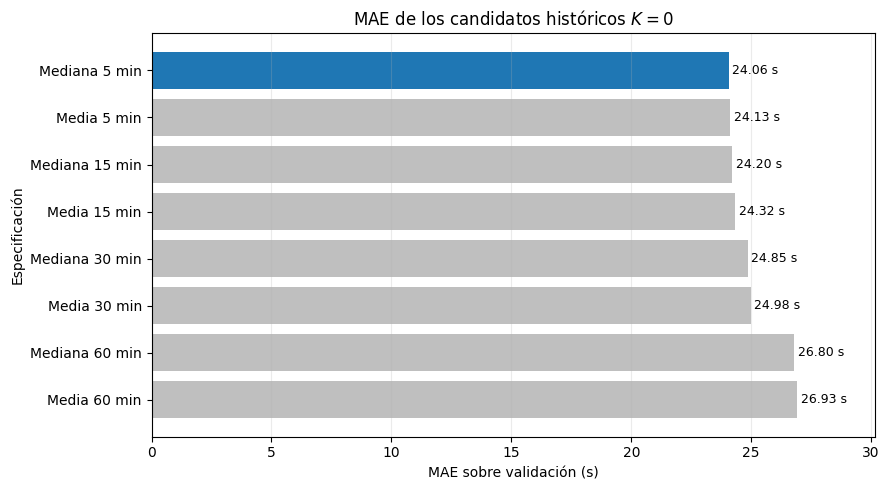

In [ ]:
# ------------------------------------------------------------
# Comparación visual de candidatos K=0
# ------------------------------------------------------------

plot_results = (
    candidate_results
    .sort_values('MAE (s)', ascending=True)
    .copy()
)

fig, ax = plt.subplots(
    figsize=(9, 5)
)

bars = ax.barh(
    plot_results['Candidato'],
    plot_results['MAE (s)'],
    color=[
        'C0' if name == 'Mediana 5 min'
        else '0.75'
        for name in plot_results['Candidato']
    ]
)

# Mejor candidato en la parte superior
ax.invert_yaxis()

# Etiquetas con el valor exacto
for bar, value in zip(
    bars,
    plot_results['MAE (s)']
):
    ax.text(
        value + 0.15,
        bar.get_y() + bar.get_height() / 2,
        f'{value:.2f} s',
        va='center',
        fontsize=9
    )

ax.set_title(
    'MAE de los candidatos históricos $K=0$'
)

ax.set_xlabel(
    'MAE sobre validación (s)'
)

ax.set_ylabel(
    'Especificación'
)

ax.grid(
    axis='x',
    alpha=0.25
)

# Espacio para las etiquetas numéricas
ax.set_xlim(
    0,
    plot_results['MAE (s)'].max() * 1.12
)

plt.tight_layout()
plt.show()

Los resultados muestran que una resolución temporal más fina mejora progresivamente la estimación histórica de los tiempos origen-destino. El mejor desempeño según la métrica principal corresponde a la mediana condicionada por día de la semana e intervalo de 5 minutos, con un MAE de 24.06 s y un WAPE de 3.97 %, lo que representa una reducción de 71.71 % en el MAE respecto de la media histórica no condicionada. La media con resolución de 5 minutos presenta un desempeño muy cercano, con un MAE apenas 0.31 % superior, y obtiene valores ligeramente menores de RMSE y del percentil 95 del error absoluto. Esta diferencia es consistente con las propiedades de ambos estadísticos: la mediana resulta particularmente adecuada cuando el MAE constituye el criterio principal de selección, mientras que la media está naturalmente más asociada a la minimización del error cuadrático. Dado que la diferencia es muy pequeña, la selección responde al criterio de MAE establecido previamente y no a una ventaja sustancial de un estadístico sobre el otro. La resolución de 5 minutos coincide además con la resolución temporal nominal del dataset y dispone de 17–18 observaciones históricas por combinación de día de la semana e intervalo durante el periodo de entrenamiento. Cabe notar que, en las resoluciones más gruesas, el mayor número de observaciones por grupo proviene de agrupar las observaciones de 5 minutos contenidas en un mismo intervalo, por lo que no representa ocurrencias temporales independientes: en todas las resoluciones el número de días distintos disponibles para cada día de la semana es el mismo. En consecuencia, se selecciona como baseline $K=0$ la mediana histórica de cada par origen-destino condicionada por día de la semana e intervalo de 5 minutos.

### 5.4 Evaluación final del baseline $K=0$

Una vez seleccionada la especificación mediante el conjunto de validación, la referencia histórica se estima nuevamente utilizando toda la información disponible entre enero y mayo de 2017. El conjunto de prueba, correspondiente a junio, se mantiene completamente fuera del proceso de selección y se utiliza únicamente en esta etapa para obtener una evaluación final fuera de muestra.

El baseline seleccionado estima cada uno de los 156 pares origen-destino mediante la mediana histórica correspondiente al mismo día de la semana y al mismo intervalo de 5 minutos. El desempeño se evalúa con MAE, RMSE, WAPE y el percentil 95 del error absoluto.

In [ ]:
# ------------------------------------------------------------
# 5.4 Evaluación final del baseline K=0
# ------------------------------------------------------------

SELECTED_RESOLUTION = 5
SELECTED_STATISTIC = 'median'


# ------------------------------------------------------------
# Reestimación con entrenamiento + validación
# ------------------------------------------------------------

train_val_od = pd.concat(
    [
        train_od,
        val_od
    ],
    axis=0
).sort_index()


final_k0_reference = (
    build_od_reference(
        train_val_od,
        SELECTED_RESOLUTION,
        SELECTED_STATISTIC
    )
)


# ------------------------------------------------------------
# Predicción sobre junio
# ------------------------------------------------------------

pred_test_k0 = (
    predict_od_reference(
        final_k0_reference,
        test_od,
        SELECTED_RESOLUTION
    )
)

y_test_od = (
    test_od.to_numpy()
)


# ------------------------------------------------------------
# Métricas finales
# ------------------------------------------------------------

final_metrics = regression_metrics(
    y_test_od,
    pred_test_k0
)

abs_error_test = np.abs(
    pred_test_k0
    - y_test_od
)


final_k0_results = pd.DataFrame([
    {
        'Modelo':
            'K=0 — Mediana día/5 min',

        **final_metrics,

        'P95 error abs. (s)':
            60
            * np.percentile(
                abs_error_test,
                95
            )
    }
])


display(
    final_k0_results.style.format({
        'MAE (min)': '{:.4f}',
        'MAE (s)': '{:.2f}',
        'RMSE (min)': '{:.4f}',
        'RMSE (s)': '{:.2f}',
        'WAPE (%)': '{:.2f}%',
        'P95 error abs. (s)': '{:.2f}'
    })
)


# ------------------------------------------------------------
# Soporte histórico de la especificación final
# ------------------------------------------------------------

final_keys = temporal_keys(
    train_val_od.index,
    SELECTED_RESOLUTION
)

final_support = (
    pd.Series(
        1,
        index=final_keys
    )
    .groupby(level=[0, 1])
    .sum()
)


print()
print(
    'Periodo de ajuste:',
    train_val_od.index.min(),
    '→',
    train_val_od.index.max()
)

print(
    'Periodo de prueba:',
    test_od.index.min(),
    '→',
    test_od.index.max()
)

print()
print(
    'Observaciones históricas por grupo:',
    f'mín={final_support.min()},',
    f'mediana={final_support.median():.0f},',
    f'máx={final_support.max()}'
)

,Modelo,MAE (min),MAE (s),RMSE (min),RMSE (s),WAPE (%),P95 error abs. (s)
0,K=0 — Mediana día/5 min,0.3851,23.11,0.9722,58.33,3.80%,114.58



Periodo de ajuste: 2017-01-01 00:00:00 → 2017-05-31 23:55:00
Periodo de prueba: 2017-06-01 00:00:00 → 2017-06-30 23:55:00

Observaciones históricas por grupo: mín=21, mediana=22, máx=22


Los resultados sobre el conjunto de prueba muestran que el baseline seleccionado mantiene un desempeño estable fuera del periodo utilizado para comparar las especificaciones. Utilizando únicamente información histórica de enero a mayo, la mediana correspondiente al mismo día de la semana e intervalo de 5 minutos obtiene en junio un MAE de 23.11 s, un RMSE de 58.33 s, un WAPE de 3.80 % y un percentil 95 del error absoluto de 114.58 s.

El desempeño es ligeramente mejor que el observado durante la validación, donde el MAE fue de 24.06 s y el WAPE de 3.97 %. Esta comparación no muestra deterioro fuera de muestra, pero debe interpretarse con cautela: se dispone de un único mes de prueba y la referencia utilizada para junio se construye con un mayor número de observaciones históricas (entre 21 y 22 por combinación de día de la semana e intervalo de 5 minutos, frente a 17–18 durante la validación). Además, parte de la diferencia puede deberse al calendario: mayo incluye un día feriado (Memorial Day) y el baseline no distingue días feriados. Por tanto, estos resultados aportan evidencia de estabilidad dentro del horizonte temporal analizado, pero no permiten descartar de manera concluyente posibles efectos de sobreajuste.

En consecuencia, el escenario $K=0$ queda establecido como una estimación puramente histórica de la matriz completa de tiempos de viaje, sin utilizar ninguna observación actual de su estado. El MAE de 23.11 s por par origen-destino constituye el nivel de referencia que deberán superar los métodos posteriores que incorporen un número reducido de observaciones actuales, $K>0$.

## 6. Síntesis del baseline $K=0$ y transición a escenarios con observaciones actuales

El baseline $K=0$ se formuló directamente sobre la matriz de tiempos de viaje entre los 13 macronodos de la red experimental. Para cada instante, el objetivo consiste en estimar los 156 tiempos origen-destino dirigidos sin disponer de ninguna observación actual de la matriz. Entre las referencias históricas evaluadas, la mejor especificación según el MAE fue la mediana histórica de cada par origen-destino condicionada por el día de la semana y por el intervalo de 5 minutos correspondiente. Esta elección es apropiada para el problema porque aprovecha únicamente patrones recurrentes disponibles antes del instante evaluado, conserva la resolución temporal nominal de 5 minutos de los datos y proporciona una referencia simple e interpretable frente a métodos posteriores de mayor complejidad.

La comparación de las referencias históricas permitió evaluar la relevancia de la información temporal utilizada por el baseline. La media histórica no condicionada obtuvo un MAE de 85.04 s sobre el conjunto de validación; al incorporar únicamente la hora del día, el error disminuyó a 46.12 s, y al considerar conjuntamente el día de la semana y la hora se redujo a 26.93 s. La evaluación posterior de resoluciones de 60, 30, 15 y 5 minutos mostró una mejora adicional conforme aumentó la granularidad temporal, hasta alcanzar un MAE de 24.06 s con la mediana de 5 minutos. Estos resultados muestran que el día de la semana y la posición temporal dentro del día contienen información relevante para estimar el estado esperado de la matriz.

El protocolo temporal separó enero–abril para entrenamiento, mayo para validación y junio para prueba, evitando que observaciones futuras intervinieran en la construcción o selección del baseline. La especificación seleccionada obtuvo en validación un MAE de 24.06 s, un RMSE de 63.73 s y un WAPE de 3.97 %. Tras reestimarla con la información disponible de enero a mayo, su evaluación final sobre junio produjo un MAE de 23.11 s, un RMSE de 58.33 s y un WAPE de 3.80 %, sin deterioro respecto del conjunto de validación. Este resultado aporta evidencia de estabilidad fuera de muestra dentro del horizonte analizado; sin embargo, debe interpretarse con cautela, ya que se dispone de un único mes de prueba y la referencia utilizada para junio se construye con un mayor número de observaciones históricas que la empleada durante la validación. Por tanto, no permite descartar de manera concluyente efectos de sobreajuste ni una posible dependencia del mes utilizado para seleccionar la especificación.

El MAE se adoptó como métrica principal debido a que expresa directamente, en unidades de tiempo, la magnitud promedio de la desviación entre los tiempos origen-destino estimados y observados. El RMSE se utilizó como medida complementaria para dar mayor peso a errores grandes, mientras que el WAPE permitió expresar el error absoluto agregado en términos relativos. Asimismo, el percentil 95 del error absoluto permite caracterizar el comportamiento de las desviaciones de mayor magnitud. Como referencia mínima se utilizó la media histórica no condicionada de cada par origen-destino; frente a ella, el baseline seleccionado redujo el MAE de validación en 71.71 %, mostrando que incluso un método histórico sencillo puede proporcionar una estimación considerablemente más informativa cuando incorpora adecuadamente la estructura temporal de la red.

Con estos resultados, el escenario $K=0$ establece el nivel de desempeño que deberán superar los métodos posteriores. En las siguientes etapas, el problema se extenderá al caso $K>0$, en el que se dispondrá de un número reducido de entradas actuales de la matriz. A partir del comportamiento histórico aprendido y de estas observaciones parciales, se buscará actualizar la estimación histórica $\hat{T}^{(0)}(t)$ para reconstruir los tiempos origen-destino restantes. De esta forma, el baseline desarrollado en este avance proporciona tanto una referencia de desempeño como un estado histórico esperado sobre el cual podrán incorporarse las nuevas observaciones.